# FastMCP Foundations

A practical introduction to building MCP servers with FastMCP — covering the protocol's architecture, core Python primitives, structured message handling, middleware patterns, observability, and production deployment. All three modules are consolidated here in sequence.

## Table of Contents

- [Module 01: Introduction to FastMCP](#module-01-introduction-to-fastmcp)
  - [Background on FastMCP](#background-on-fastmcp)
  - [Overview of MCP](#overview-of-mcp)
  - [MCP Architecture](#mcp-architecture)
  - [FastMCP Pros, Cons, and Use Cases](#fastmcp-pros-cons-and-use-cases)
  - [MCP and the Agentic AI Ecosystem](#mcp-and-the-agentic-ai-ecosystem)
  - [Alternatives to MCP](#alternatives-to-mcp)
  - [Real-world Use Cases](#real-world-use-cases)
- [Module 02: FastMCP Essentials](#module-02-fastmcp-essentials)
  - [FastMCP vs Standard MCP](#fastmcp-vs-standard-mcp)
  - [Connecting to an MCP Server](#connecting-to-an-mcp-server)
  - [Building MCP Servers](#building-mcp-servers)
  - [Tools vs Resources](#tools-vs-resources)
  - [Chaining Tools](#chaining-tools)
- [Module 03: Metrics and Observability for FastMCP](#module-03-metrics-and-observability-for-fastmcp)
  - [Structured Message Handling](#structured-message-handling)
  - [Middleware and Plugins](#middleware-and-plugins)
  - [State and Persistence](#state-and-persistence)
  - [Integrations](#integrations)
  - [Typed Configuration](#typed-configuration)
  - [Custom Middleware Patterns](#custom-middleware-patterns)
  - [Debug Mode and Observability](#debug-mode-and-observability)
  - [Security and Policy Enforcement](#security-and-policy-enforcement)
  - [FastMCP in Production](#fastmcp-in-production)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

---

## Module 01: Introduction to FastMCP

FastMCP is a high-level Python framework that makes it fast to build Model Context Protocol (MCP) servers — the open standard that lets AI models interact with external tools and data sources through a common interface.

### Background on FastMCP

FastMCP is an open-source project built on top of Anthropic's Model Context Protocol. It emerged from the need to reduce the boilerplate involved in writing MCP servers by hand, offering a decorator-based API similar to Express.js or FastAPI.

Key reasons for its popularity:
- **Rapid development** — a working MCP server in minutes rather than hours
- **Vibrant ecosystem** — active community, growing library of example servers
- **Best-practice defaults** — schema validation, structured outputs, and error handling baked in

**Resources:**
- [MCP announcement blog post](https://www.anthropic.com/news/model-context-protocol)
- [MCP documentation](https://modelcontextprotocol.io/docs/getting-started/intro)
- [FastMCP documentation](https://gofastmcp.com/getting-started/welcome)
- [Course code repository](https://github.com/ttaulli/fastmcp-course-code)

### Overview of MCP

MCP (Model Context Protocol) was launched by Anthropic in November 2024 and has since been adopted by OpenAI, Google, and Microsoft. It defines a standard protocol that allows AI assistants to connect to external tools, data sources, and services.

#### The MxN Problem

Before MCP, every AI model needed a custom integration with every tool — M models × N tools = M×N connectors to build and maintain. MCP replaces that with a single standard layer: any compliant model can use any compliant server.


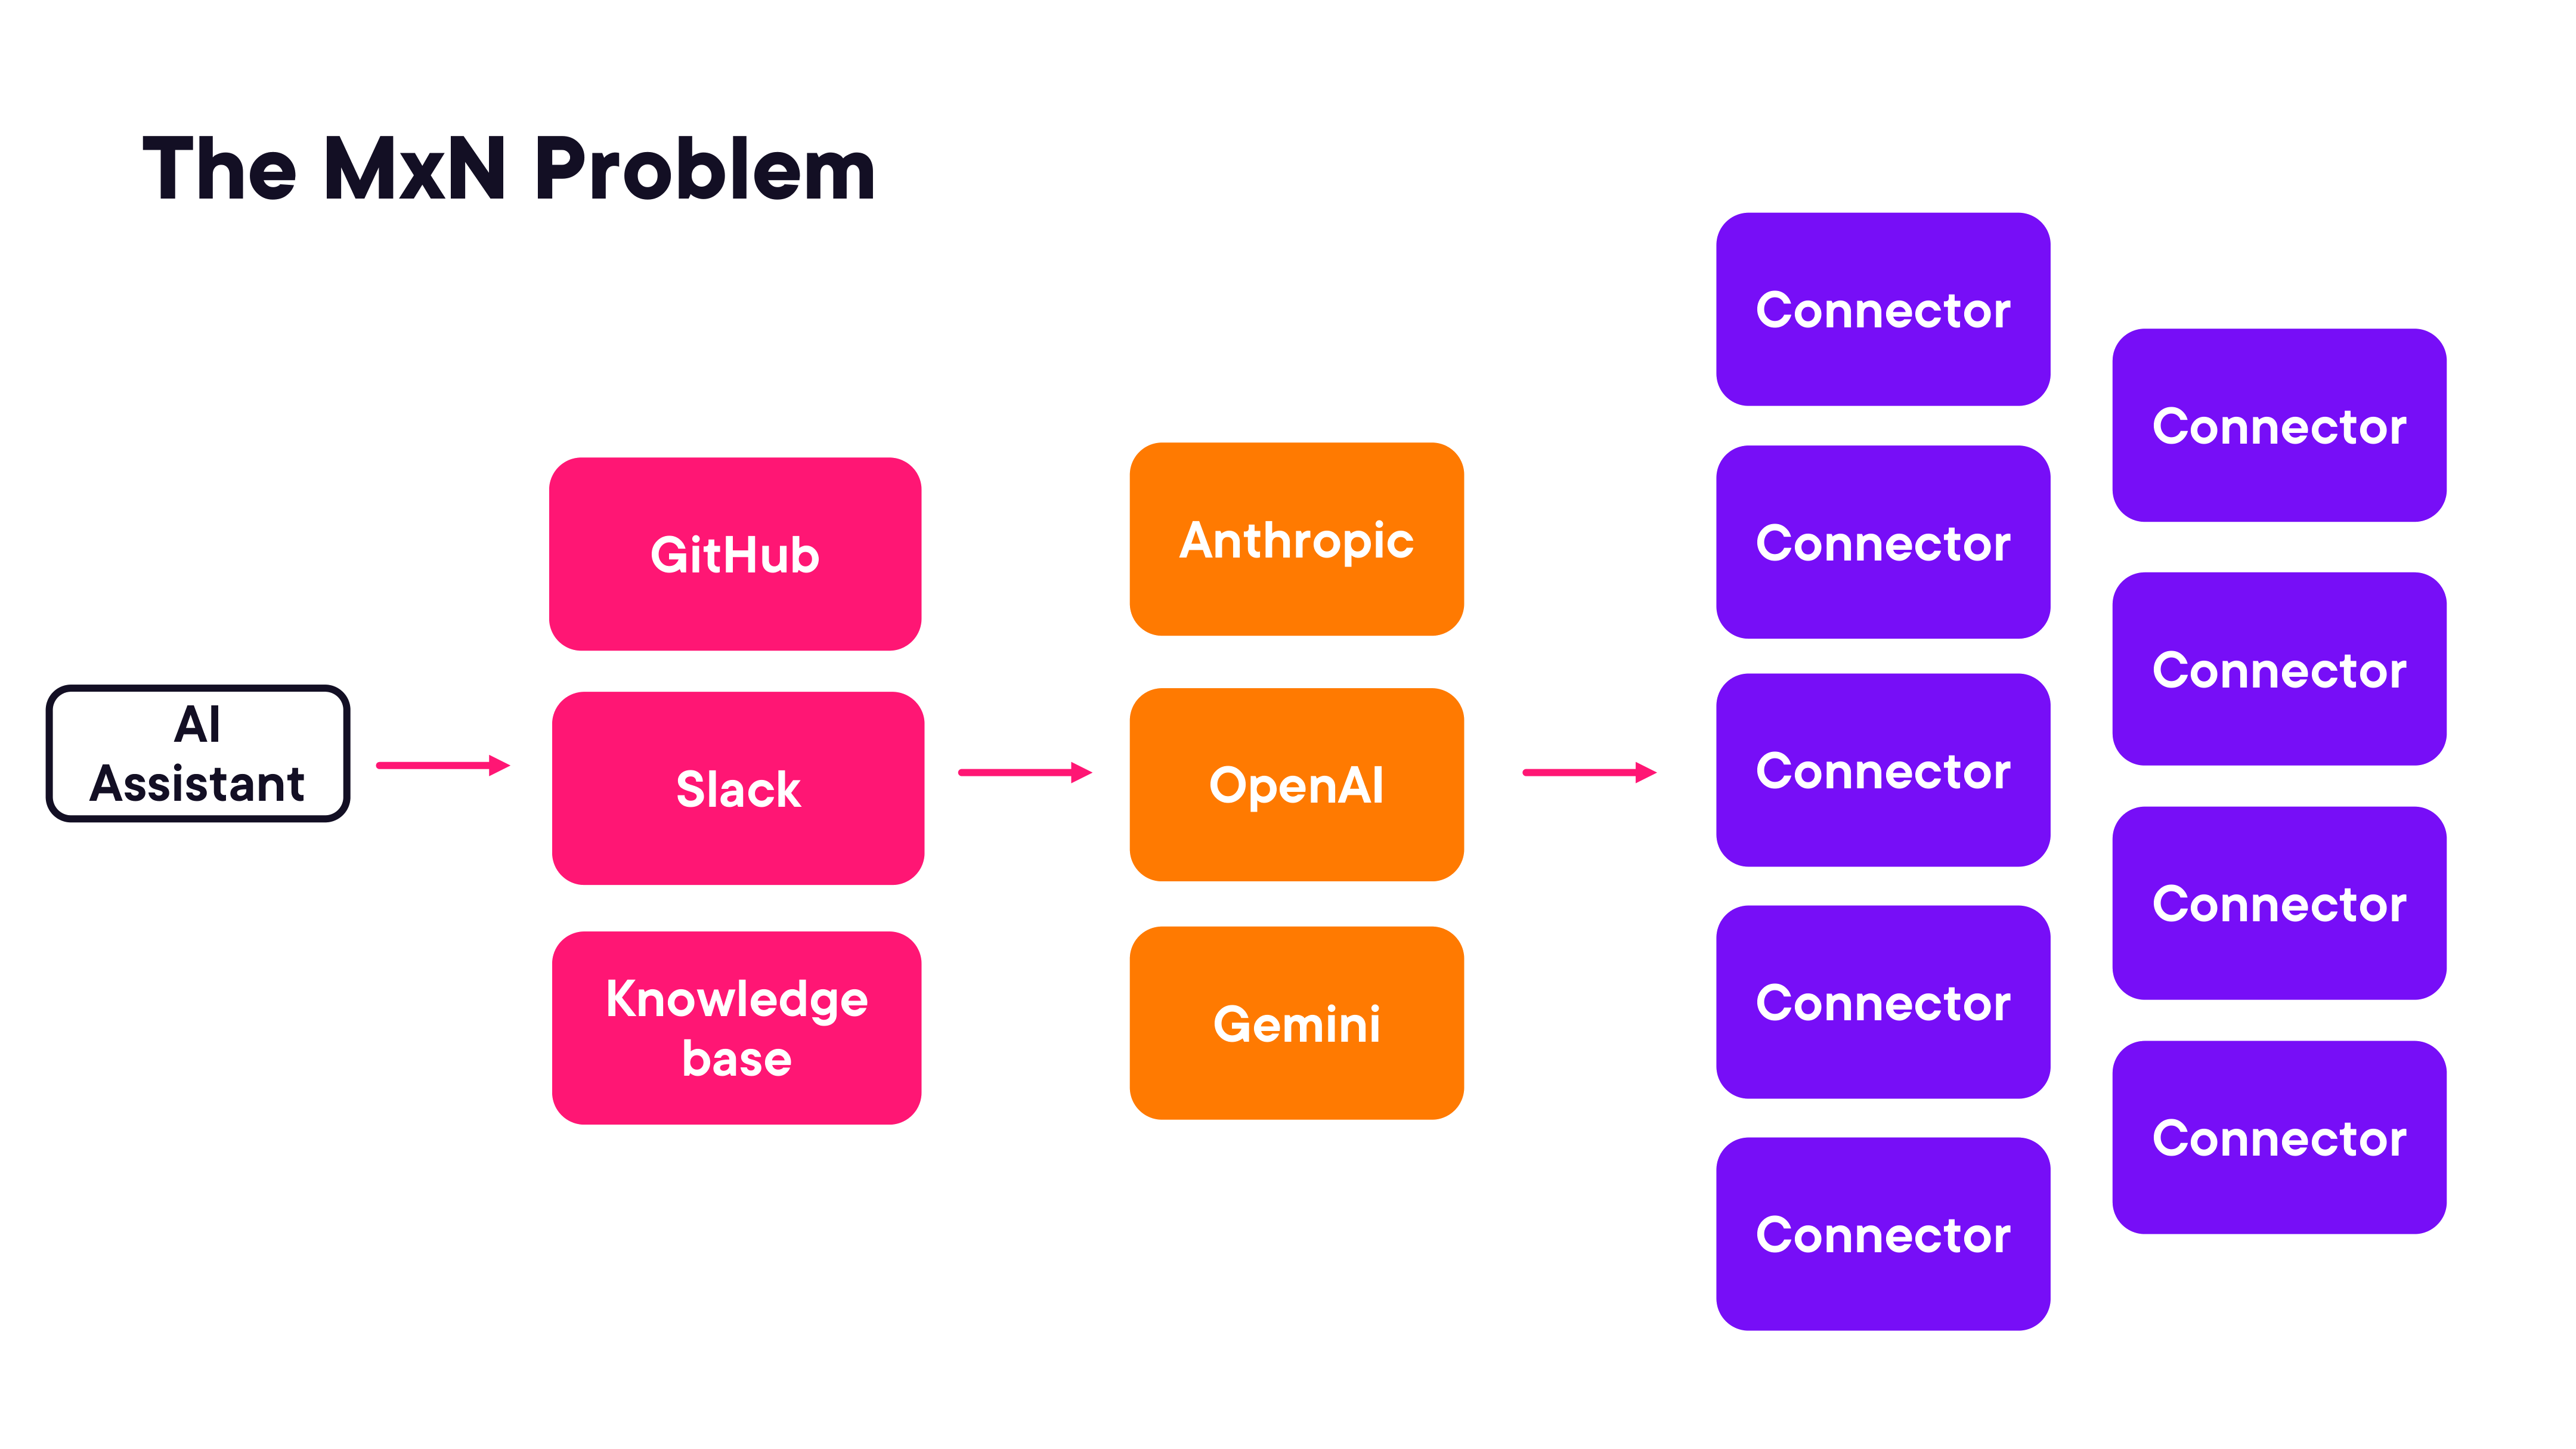

In [2]:
render_diagram(Path("assets/01-mxn-problem.png"))

#### The MCP Approach

MCP solves the MxN problem by acting as a standard middleware layer:

- **Easier integration** — build the connector once per tool, use it from any model
- **Layer between models and tools** — models don't call APIs directly; they call MCP tools
- **Runs on cloud and local machines** — transports include stdio, SSE, and Streamable HTTP
- **Not starting from scratch** — reuse existing MCP servers from the community

#### MCP and Agentic AI

MCP enables multi-step agentic workflows. For example, when a user says "My package never arrived, but I was billed," an agentic AI can: understand the intent → plan next steps → resolve the issue — all by orchestrating MCP tool calls rather than hard-coded API calls.

### MCP Architecture

#### Traditional LLM Architecture

In a traditional setup, the user communicates with a host application, which passes requests directly down to the LLM. There are no standard tool integrations — each one is bespoke.


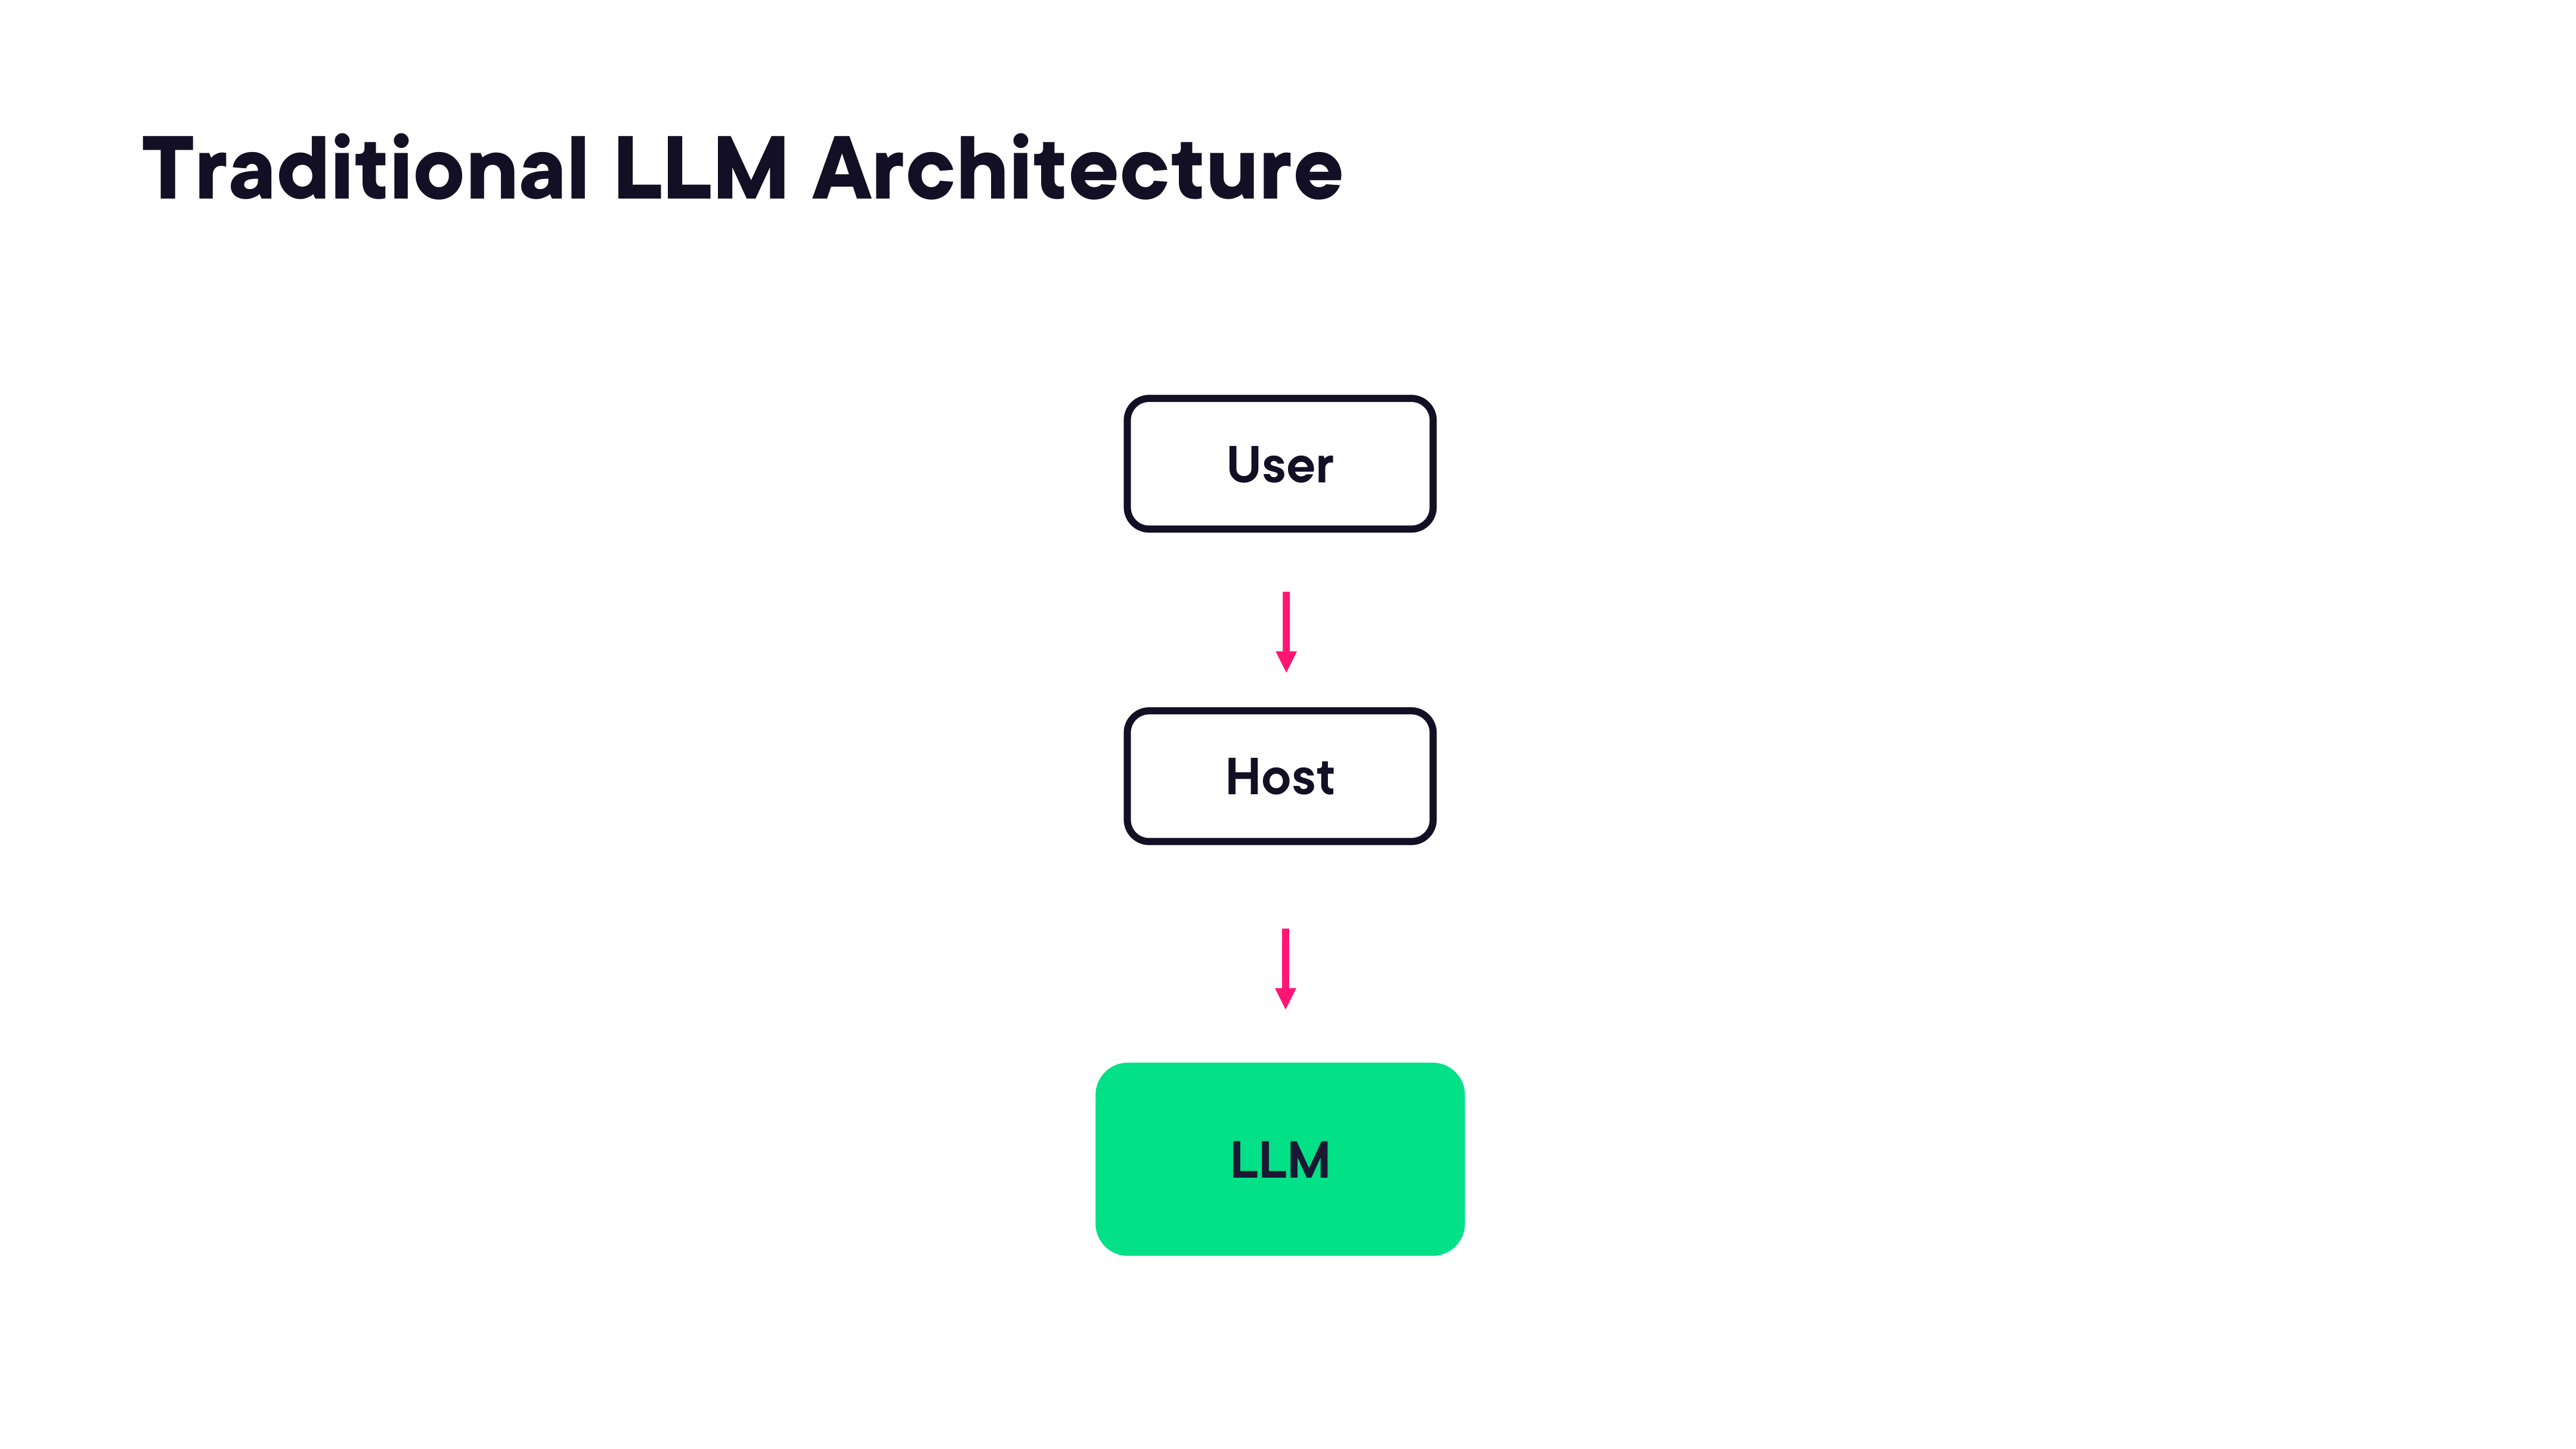

In [3]:
render_diagram(Path("assets/02-traditional-llm-architecture.png"), width=600)

#### Client–Host–Server Architecture

MCP introduces a three-tier architecture. The **MCP host** (e.g. Claude Desktop, VS Code) embeds multiple **MCP clients**, each connected to a separate **MCP server**. Each server exposes **Tools**, **Resources**, and **Prompts** over one of three transports:

| Transport | Description |
|---|---|
| **Stdio** | Standard input/output — for local processes |
| **SSE** | Server-Sent Events — for streaming over HTTP |
| **Streamable HTTP** | Modern bidirectional HTTP streaming |

FastMCP's Streamable HTTP transport shares design patterns with FastAPI — both use async/await and HTTP endpoints with streaming support.


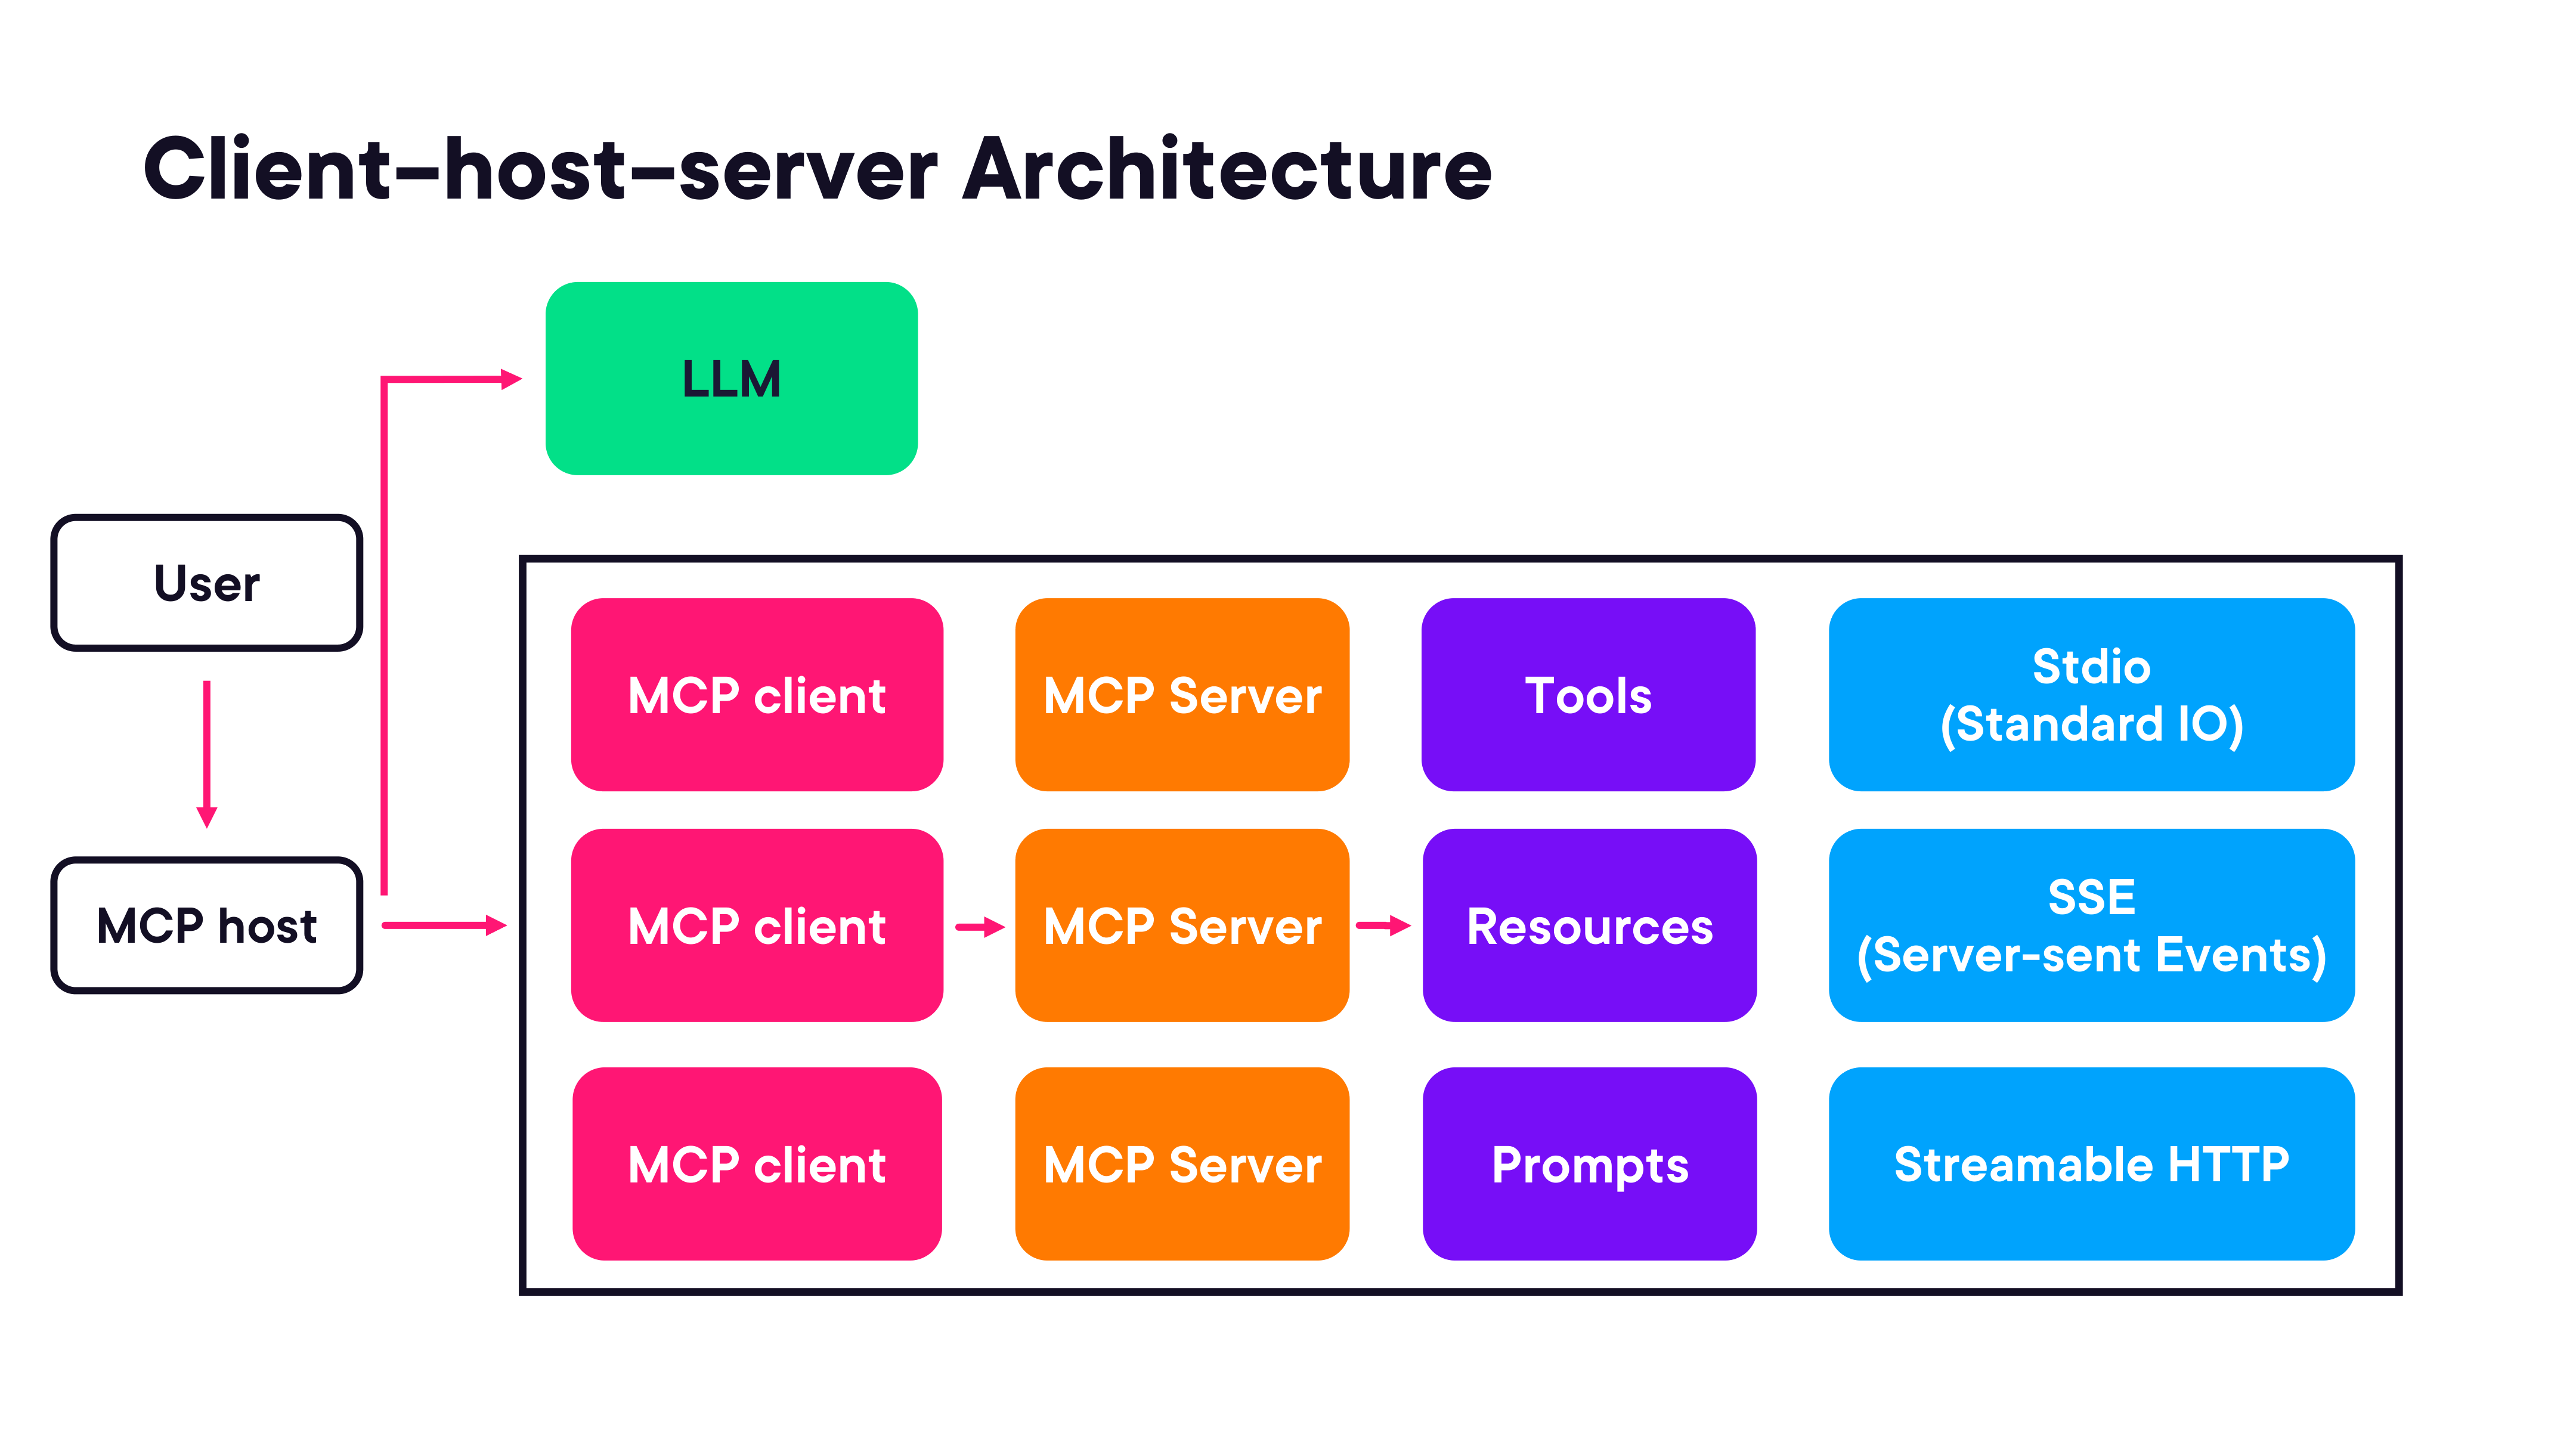

In [4]:
render_diagram(Path("assets/03-client-host-server-architecture.png"))

### FastMCP Pros, Cons, and Use Cases

#### FastMCP vs the Raw MCP SDK

| Pros | Cons |
|---|---|
| Rapid development and reduced complexity | Less flexibility for edge cases |
| Easier onboarding (similar to Express.js) | Evolving features — occasional breaking changes |
| Focus on best practices | Learning curve for developers unfamiliar with Express-style frameworks |
| Consistent, opinionated API | Performance overhead vs raw SDK |
| | Dependency risk |
| | Security risks if misused |
| | Limited support for enterprise-specific needs |

#### Ideal Use Cases

FastMCP is best suited for:
- **Prototypes** — quickly validate an idea
- **Hackathons** — ship a working MCP server in hours
- **MVPs** — minimum viable products that need real integrations fast
- **Students and learners** — approachable API for learning MCP concepts

### Demo: Setting Up FastMCP

Install FastMCP with pip, then create a minimal server:

```bash
pip install fastmcp
```

```python
from fastmcp import FastMCP

mcp = FastMCP("My Server")

@mcp.tool
def hello(name: str) -> str:
    """Say hello to someone."""
    return f"Hello, {name}!"

if __name__ == "__main__":
    mcp.run()
```

Run it locally: `python server.py` — the server starts on stdio by default, ready for any MCP client to connect.

### MCP and the Agentic AI Ecosystem

MCP sits at the **protocols** layer of the modern agentic AI stack. The full stack looks like:

| Layer | Examples |
|---|---|
| **Frameworks** | LangChain, LangGraph, CrewAI, AutoGen |
| **No-code / Low-code** | n8n, Zapier |
| **Protocols** | MCP, UTCP, A2A |

MCP servers do not live in isolation — they integrate with platforms like Claude Desktop, Claude Code, ChatGPT, and Cursor via their MCP client implementations.

### Alternatives to MCP

#### Framework-based Alternatives

- **Agent2Agent (A2A)** — Google's protocol for agent-to-agent communication
- **Agentica** — framework-level agent communication
- **Universal Tool Calling Protocol (UTCP)** — aims to be model-agnostic

#### HTTP-based Alternatives

- **REST API–style approaches** — URL-based function calling without a standard schema
- **Agent Communication Protocol (ACP)** — HTTP-native protocol
- **Webhook-style integrations** — event-driven, but stateless and harder to compose

MCP's advantage over these is standardisation: a single client can discover and call any compliant server's tools without bespoke integration code.

### Real-world Use Cases

#### Walmart

Walmart has rolled out MCP across its organisation to consolidate AI agents. Key aspects of their adoption:
- Agents share a common MCP interface, reducing integration complexity
- Uses the **Goose** open-source platform for agent orchestration
- Internally authored MCP servers for common enterprise tasks

#### Block

Block deployed MCP for common internal tasks, authoring their own servers and rolling them out organisation-wide.

#### TrueFoundry — MCP Gateway

TrueFoundry built an MCP Gateway offering:
- **Centralised MCP registry** — discover all available servers in one place
- **Playground interface** — test tools interactively
- **Observability and governance** — track usage, enforce policies
- Useful for enterprises managing many MCP servers across teams

---

## Module 02: FastMCP Essentials

This module covers the core FastMCP programming model — decorators, tools, resources, and how to connect a server to real MCP clients like VS Code, Claude Desktop, and ChatGPT.

### FastMCP vs Standard MCP

#### Standard MCP Workflow (without FastMCP)

Building a server with the raw MCP SDK requires:
1. Define tools and their schemas manually in JSON Schema
2. Write boilerplate request/response handlers for every tool
3. Manually manage structured outputs and error serialisation
4. Juggle multiple low-level concerns (routing, validation, transport)

#### FastMCP Approach — Simple Decorators

FastMCP replaces all of this with a single decorator. Python type annotations become the schema automatically:

```python
from fastmcp import FastMCP

mcp = FastMCP("My Server")

@mcp.tool
def square_number(x: int) -> int:
    """
    Returns the square of a number.

    Args:
        x: An integer to square.

    Returns:
        The squared value of x.
    """
    return x * x

if __name__ == "__main__":
    mcp.run()
```

The docstring becomes the tool description exposed to the LLM. The type annotations generate the JSON Schema input/output specs. No boilerplate required.

### Connecting to an MCP Server

FastMCP servers can be connected to any MCP-compatible client. The three most common are:

#### VS Code

VS Code has a built-in MCP directory. Add your server to the workspace MCP config and VS Code will discover and display its tools in Copilot.

- [VS Code MCP directory](https://code.visualstudio.com/mcp)

#### Claude Desktop

Claude Desktop supports MCP servers configured in `~/Library/Application Support/Claude/claude_desktop_config.json` (macOS). Each server entry specifies the command to launch it.

- [Claude Desktop download](https://claude.ai/download)
- [Node.js installation](https://nodejs.org/en/download) (required for some MCP servers)

#### ChatGPT

ChatGPT supports MCP via its plugin/tool infrastructure. Connect your FastMCP server using the Streamable HTTP transport so ChatGPT can reach it over the network.

#### Example: Time Functions Server

A minimal server exposing time-related tools:

```python
# time-mcp.py — see fastmcp-course-demos/time-mcp.py
from fastmcp import FastMCP
from datetime import datetime, timezone

mcp = FastMCP("Time MCP")

@mcp.tool
def current_utc_time() -> str:
    """Return the current UTC time as an ISO 8601 string."""
    return datetime.now(timezone.utc).isoformat()

if __name__ == "__main__":
    mcp.run()
```

### Building MCP Servers

#### Demo: Password Generator MCP Server

A server that generates cryptographically secure passwords with configurable length, character sets, and entropy reporting. It uses Python's `secrets` module so passwords are suitable for production use.

See [`fastmcp-course-demos/password_server.py`](fastmcp-course-demos/password_server.py) for the full implementation.

```python
# Excerpt from password_server.py
from fastmcp import FastMCP
import secrets, math

mcp = FastMCP("Password Generator")

@mcp.tool
def generate_password(
    length: int = 16,
    use_upper: bool = True,
    use_digits: bool = True,
    use_symbols: bool = True,
    exclude_ambiguous: bool = False,
) -> dict:
    """Generate a secure random password with entropy reporting."""
    # ... builds character pool, samples with secrets.choice, computes entropy
```

#### Demo: Weather MCP Server

A simulated weather server exposing current conditions and multi-day forecasts. Demonstrates typed dataclass return values and structured output — FastMCP serialises Python dataclasses to JSON automatically.

See [`fastmcp-course-demos/weather_server.py`](fastmcp-course-demos/weather_server.py).

#### Demo: Crypto Price MCP Server

Connects to the CoinMarketCap API to return live Bitcoin prices in multiple currencies. Requires a `CMC_API_KEY` environment variable.

- [CoinMarketCap API](https://coinmarketcap.com/api/)

See [`fastmcp-course-demos/btc_price_server.py`](fastmcp-course-demos/btc_price_server.py).

### Tools vs Resources

MCP distinguishes between two types of server capabilities:

| Concept | Description | Example |
|---|---|---|
| **Tools** | Functions called on demand by the LLM | `"Get me the current Bitcoin price."` |
| **Resources** | URI-addressable data the LLM can read | `doc://project/plan`, `help://article/123` |

Tools are imperative — the model calls them when it decides to. Resources are declarative — the model reads them like documents. Use tools for actions and computations; use resources for static or semi-static data.

#### Demo: Document and Knowledge Base MCP Server

A server that manages project documents and help articles using URI-based resources alongside tool functions for CRUD operations.

See [`fastmcp-course-demos/mcp_docs_server.py`](fastmcp-course-demos/mcp_docs_server.py).

### Chaining Tools

MCP tools can call other tools, enabling multi-step workflows. A trend server, for example, might call the price server once per day over a week to build a price history, then compute a moving average — all driven by a single user prompt.

#### Demo: Chaining Tools with a Crypto MCP

The Bitcoin trend server demonstrates tool chaining: it fetches price snapshots across multiple time points and aggregates them into trend data.

See [`fastmcp-course-demos/btc_trend_server.py`](fastmcp-course-demos/btc_trend_server.py).

---

## Module 03: Metrics and Observability for FastMCP

This module covers advanced FastMCP topics: structured message handling with Pydantic, middleware patterns, plugins, state management, integrations, typed configuration, observability, security, and production deployment.

### Structured Message Handling

Messages are at the core of MCP. FastMCP provides structured output automatically, but developers are responsible for validating structured input. Pydantic is the recommended tool.

#### Message Envelope

A `MessageEnvelope` model validates the outer wrapper of every request:

```python
from pydantic import BaseModel
from typing import Literal

class MessageEnvelope(BaseModel):
    version: str
    msg_id: str
    type: Literal["request", "response", "error"]
    payload: dict
```

```python
raw = {
    "version": "1.0",
    "msg_id": "12345",
    "type": "request",
    "payload": {"order_id": "A100", "items": ["book"], "total": 19.99}
}
msg = MessageEnvelope(**raw)  # raises ValidationError if invalid
```

#### Typed Payload Models

Nest typed models inside the envelope for full validation of the payload:

```python
class OrderPayload(BaseModel):
    order_id: str
    items: list[str]
    total: float
```

#### Safe Retries and Reliable Tracking

Each client generates a UUID `msg_id` for every request. Servers log received IDs and skip duplicate processing when the same `msg_id` arrives again — this makes retries safe even if the network drops and resends a request.

#### Structured Errors

```python
class ErrorPayload(BaseModel):
    code: str
    message: str
```

Using a typed error payload means clients can parse and handle errors programmatically rather than parsing free-form strings.

### Middleware and Plugins

#### What Is Middleware in FastMCP?

Middleware intercepts every message that passes through your MCP server before it reaches a tool. Common uses: authentication, rate limiting, logging, and request tracing.

#### Demo: Using Middleware in FastMCP

See [`fastmcp-course-demos/middleware_server.py`](fastmcp-course-demos/middleware_server.py) for a working example that combines logging middleware with structured request/response inspection.

#### What Is a Plugin in FastMCP?

A plugin is a modular piece of functionality that can be dropped into an MCP server — essentially a self-contained group of tools and resources. Plugins let you compose servers from reusable building blocks.

**Plugin examples:**

- [`fastmcp-course-demos/weather_plugins.py`](fastmcp-course-demos/weather_plugins.py) — weather tools as a plugin
- [`fastmcp-course-demos/sentiment_plugin.py`](fastmcp-course-demos/sentiment_plugin.py) — sentiment analysis plugin
- [`fastmcp-course-demos/translate_plugin.py`](fastmcp-course-demos/translate_plugin.py) — foreign language translation plugin

### State and Persistence

FastMCP tools are plain Python functions — they can read and write module-level or database-backed state between calls. This enables conversational tools that remember context across multiple user turns.


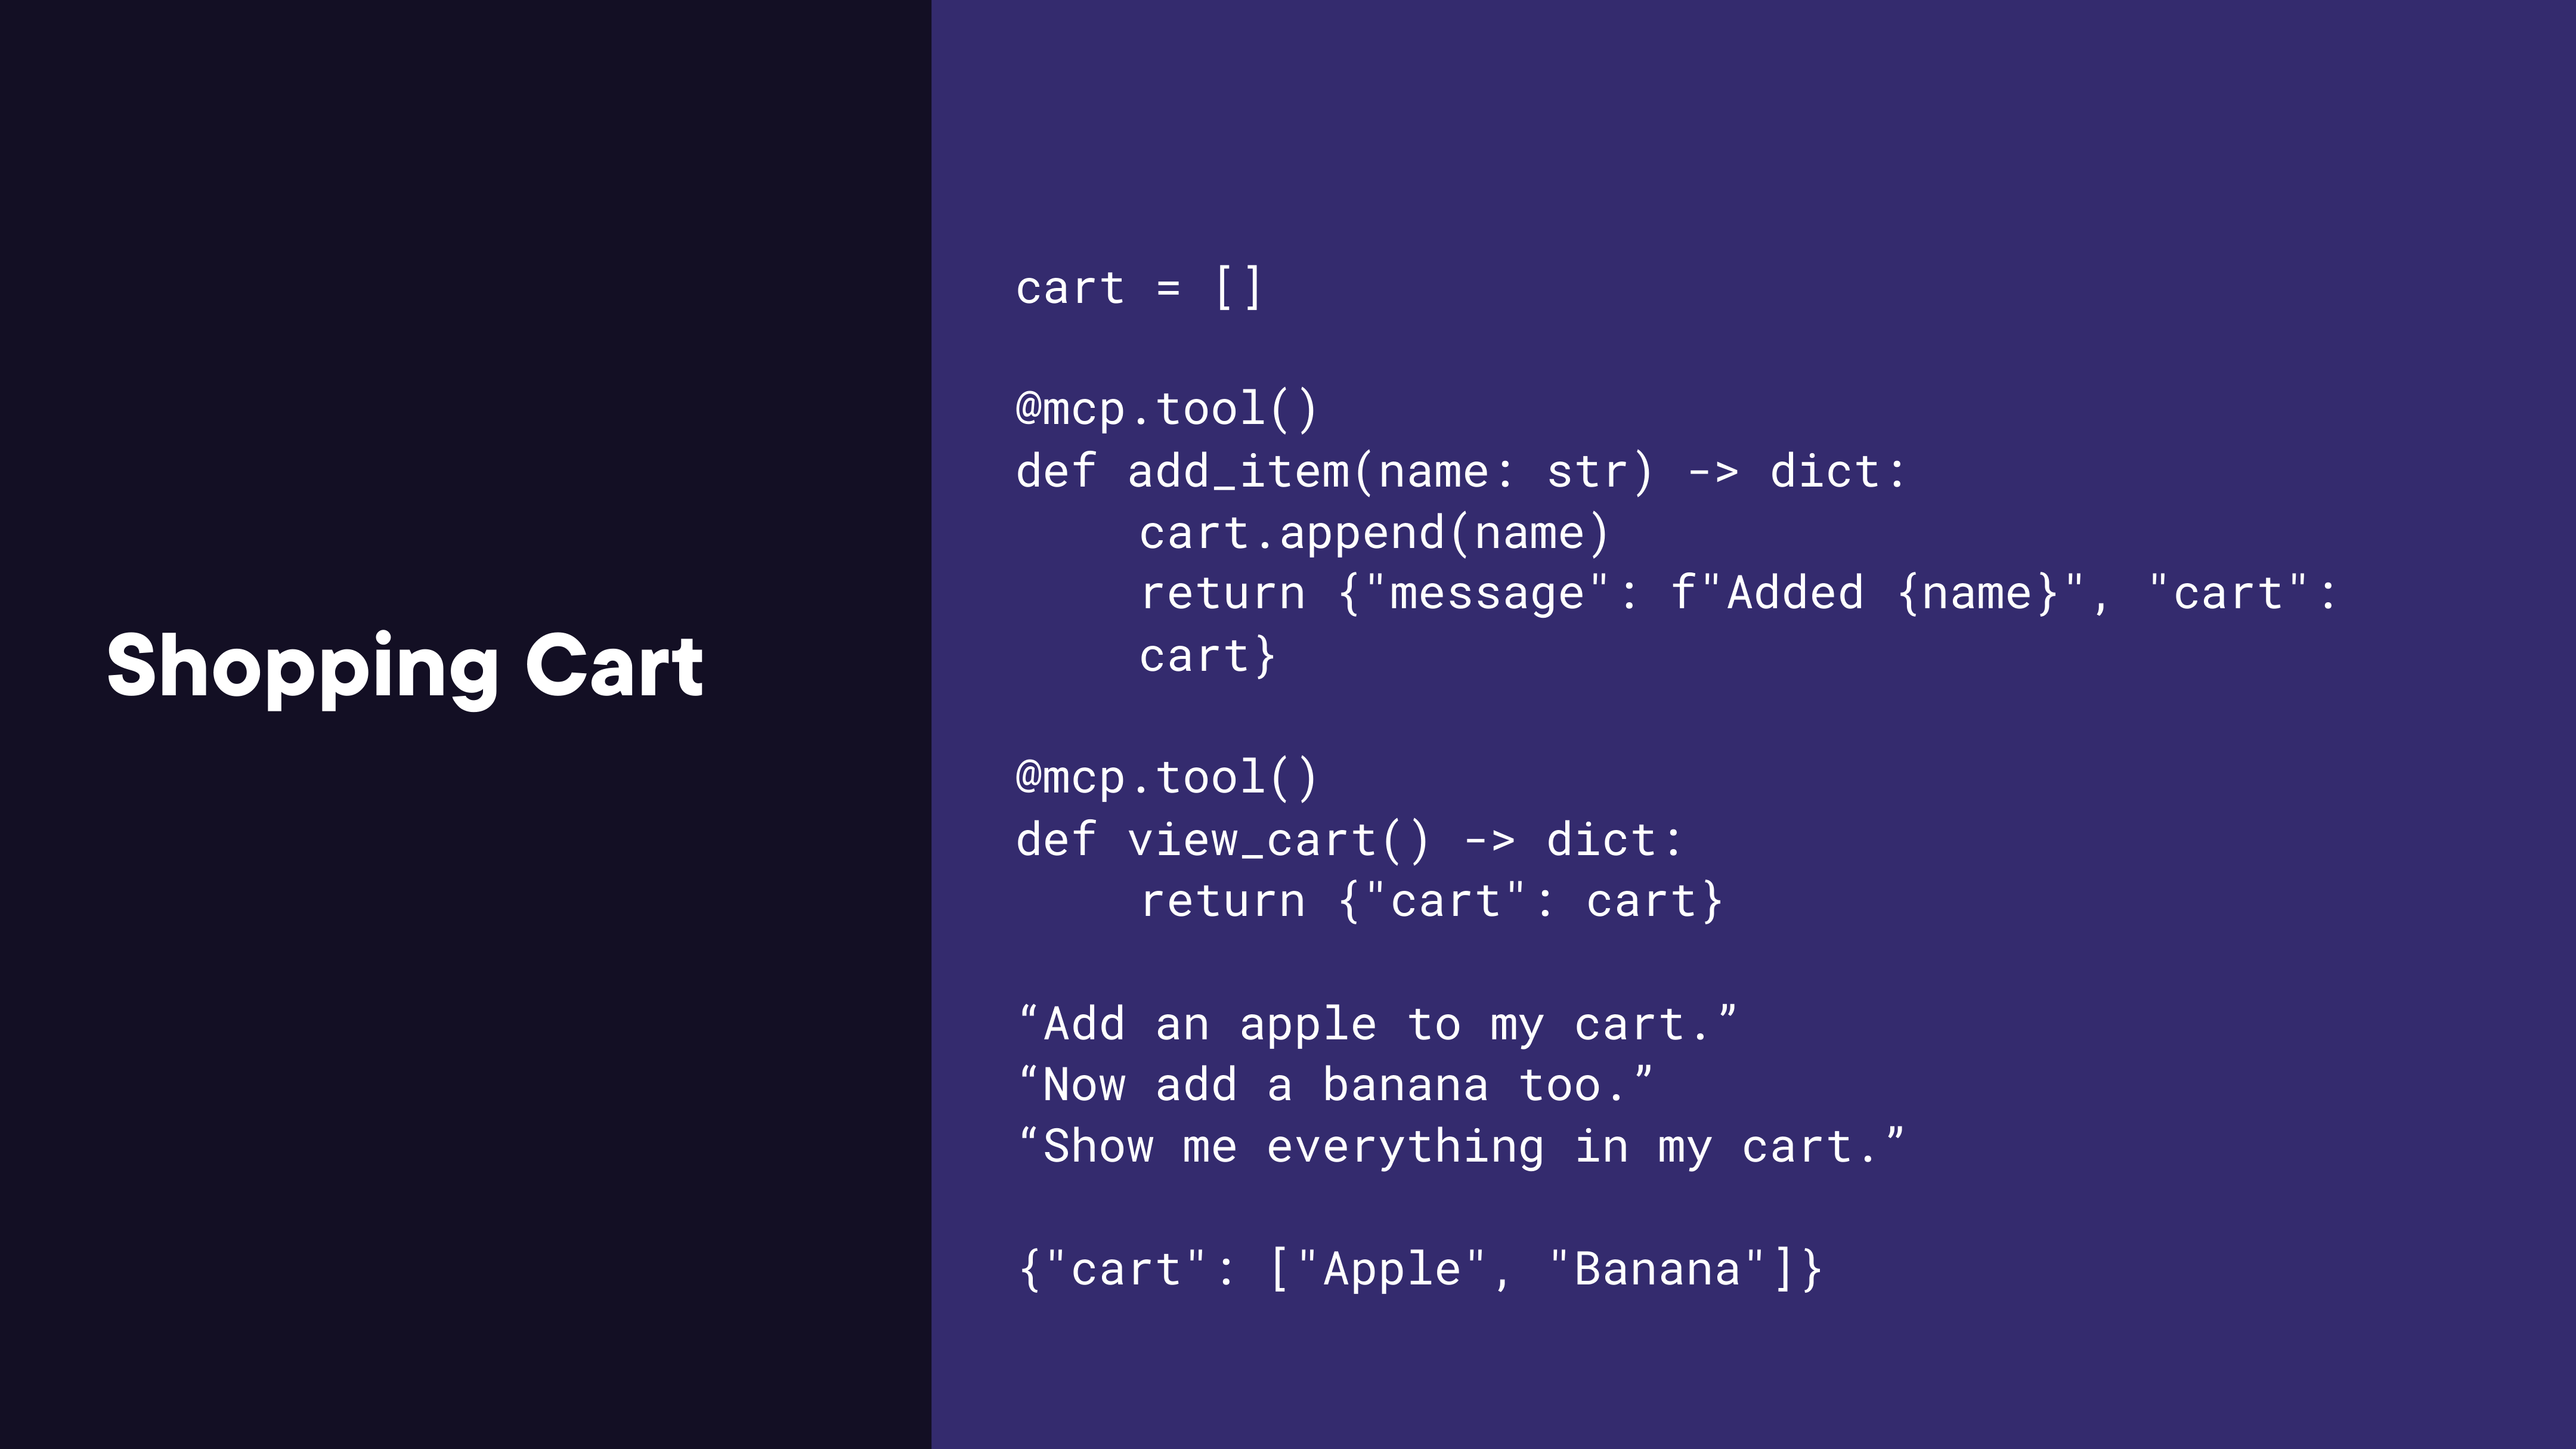

In [5]:
render_diagram(Path("assets/04-shopping-cart-state.png"))

The shopping cart example holds state in a module-level list. A conversational session like "Add an apple" → "Add a banana" → "Show cart" works because the list persists between tool calls within the same server process. For multi-process or cloud deployments, replace the in-memory list with a database or Redis.

### Integrations

MCP servers become more powerful when integrated with external systems. FastMCP supports four categories of integration:

| Category | Description | Examples |
|---|---|---|
| **Authentication** | Verify users without building login features yourself | OAuth (built-in), JWT |
| **Authorization** | Enforce access policies, separate from business logic | Eunomia, Permit.io |
| **AI and Assistants** | Connect to LLM platforms | Claude Desktop, Claude Code, ChatGPT, Cursor |
| **API and Frameworks** | Interoperate with existing APIs | OpenAPI, REST APIs |

OAuth is integrated by default in FastMCP, and FastMCP Cloud adds an additional security layer on top.

### Typed Configuration

#### `fastmcp.Config` for Environment-driven Settings

`fastmcp.Config` is a Pydantic-based configuration class. Subclass it to define your server's settings with automatic validation, type coercion, and environment variable loading:

```python
from fastmcp import Config

class Settings(Config):
    openai_api_key: str
    database_url: str
    environment: str = "production"

config = Settings()  # reads from environment variables automatically
```

#### Injecting Configuration into Tools

Inject the config instance as a default argument — FastMCP will not expose it as a tool parameter to the LLM:

```python
from fastmcp import tool

@tool
def summarize_text(text: str, config: Settings = config) -> str:
    print(f"Running in {config.environment} mode.")
    return f"Summary of {text[:30]}..."
```

#### Environment-specific Overrides

Use `.env` files or shell environment variables to switch settings between environments:

```bash
# development
ENVIRONMENT=local
DEBUG=true

# production
ENVIRONMENT=prod
DEBUG=false
```

#### Putting It Together

```bash
uvx mcp run config_server.py
# Prompt: "Use show_config_info"
# Response: {"environment": "production", "api_key_prefix": "sk-abc..."}
```

### Custom Middleware Patterns

Middleware in FastMCP subclasses `Middleware` and overrides hook methods like `on_message` and `on_call_tool`. Multiple middleware are chained in registration order.

#### Authentication Middleware

Validates an API key from the message headers before the request reaches any tool:


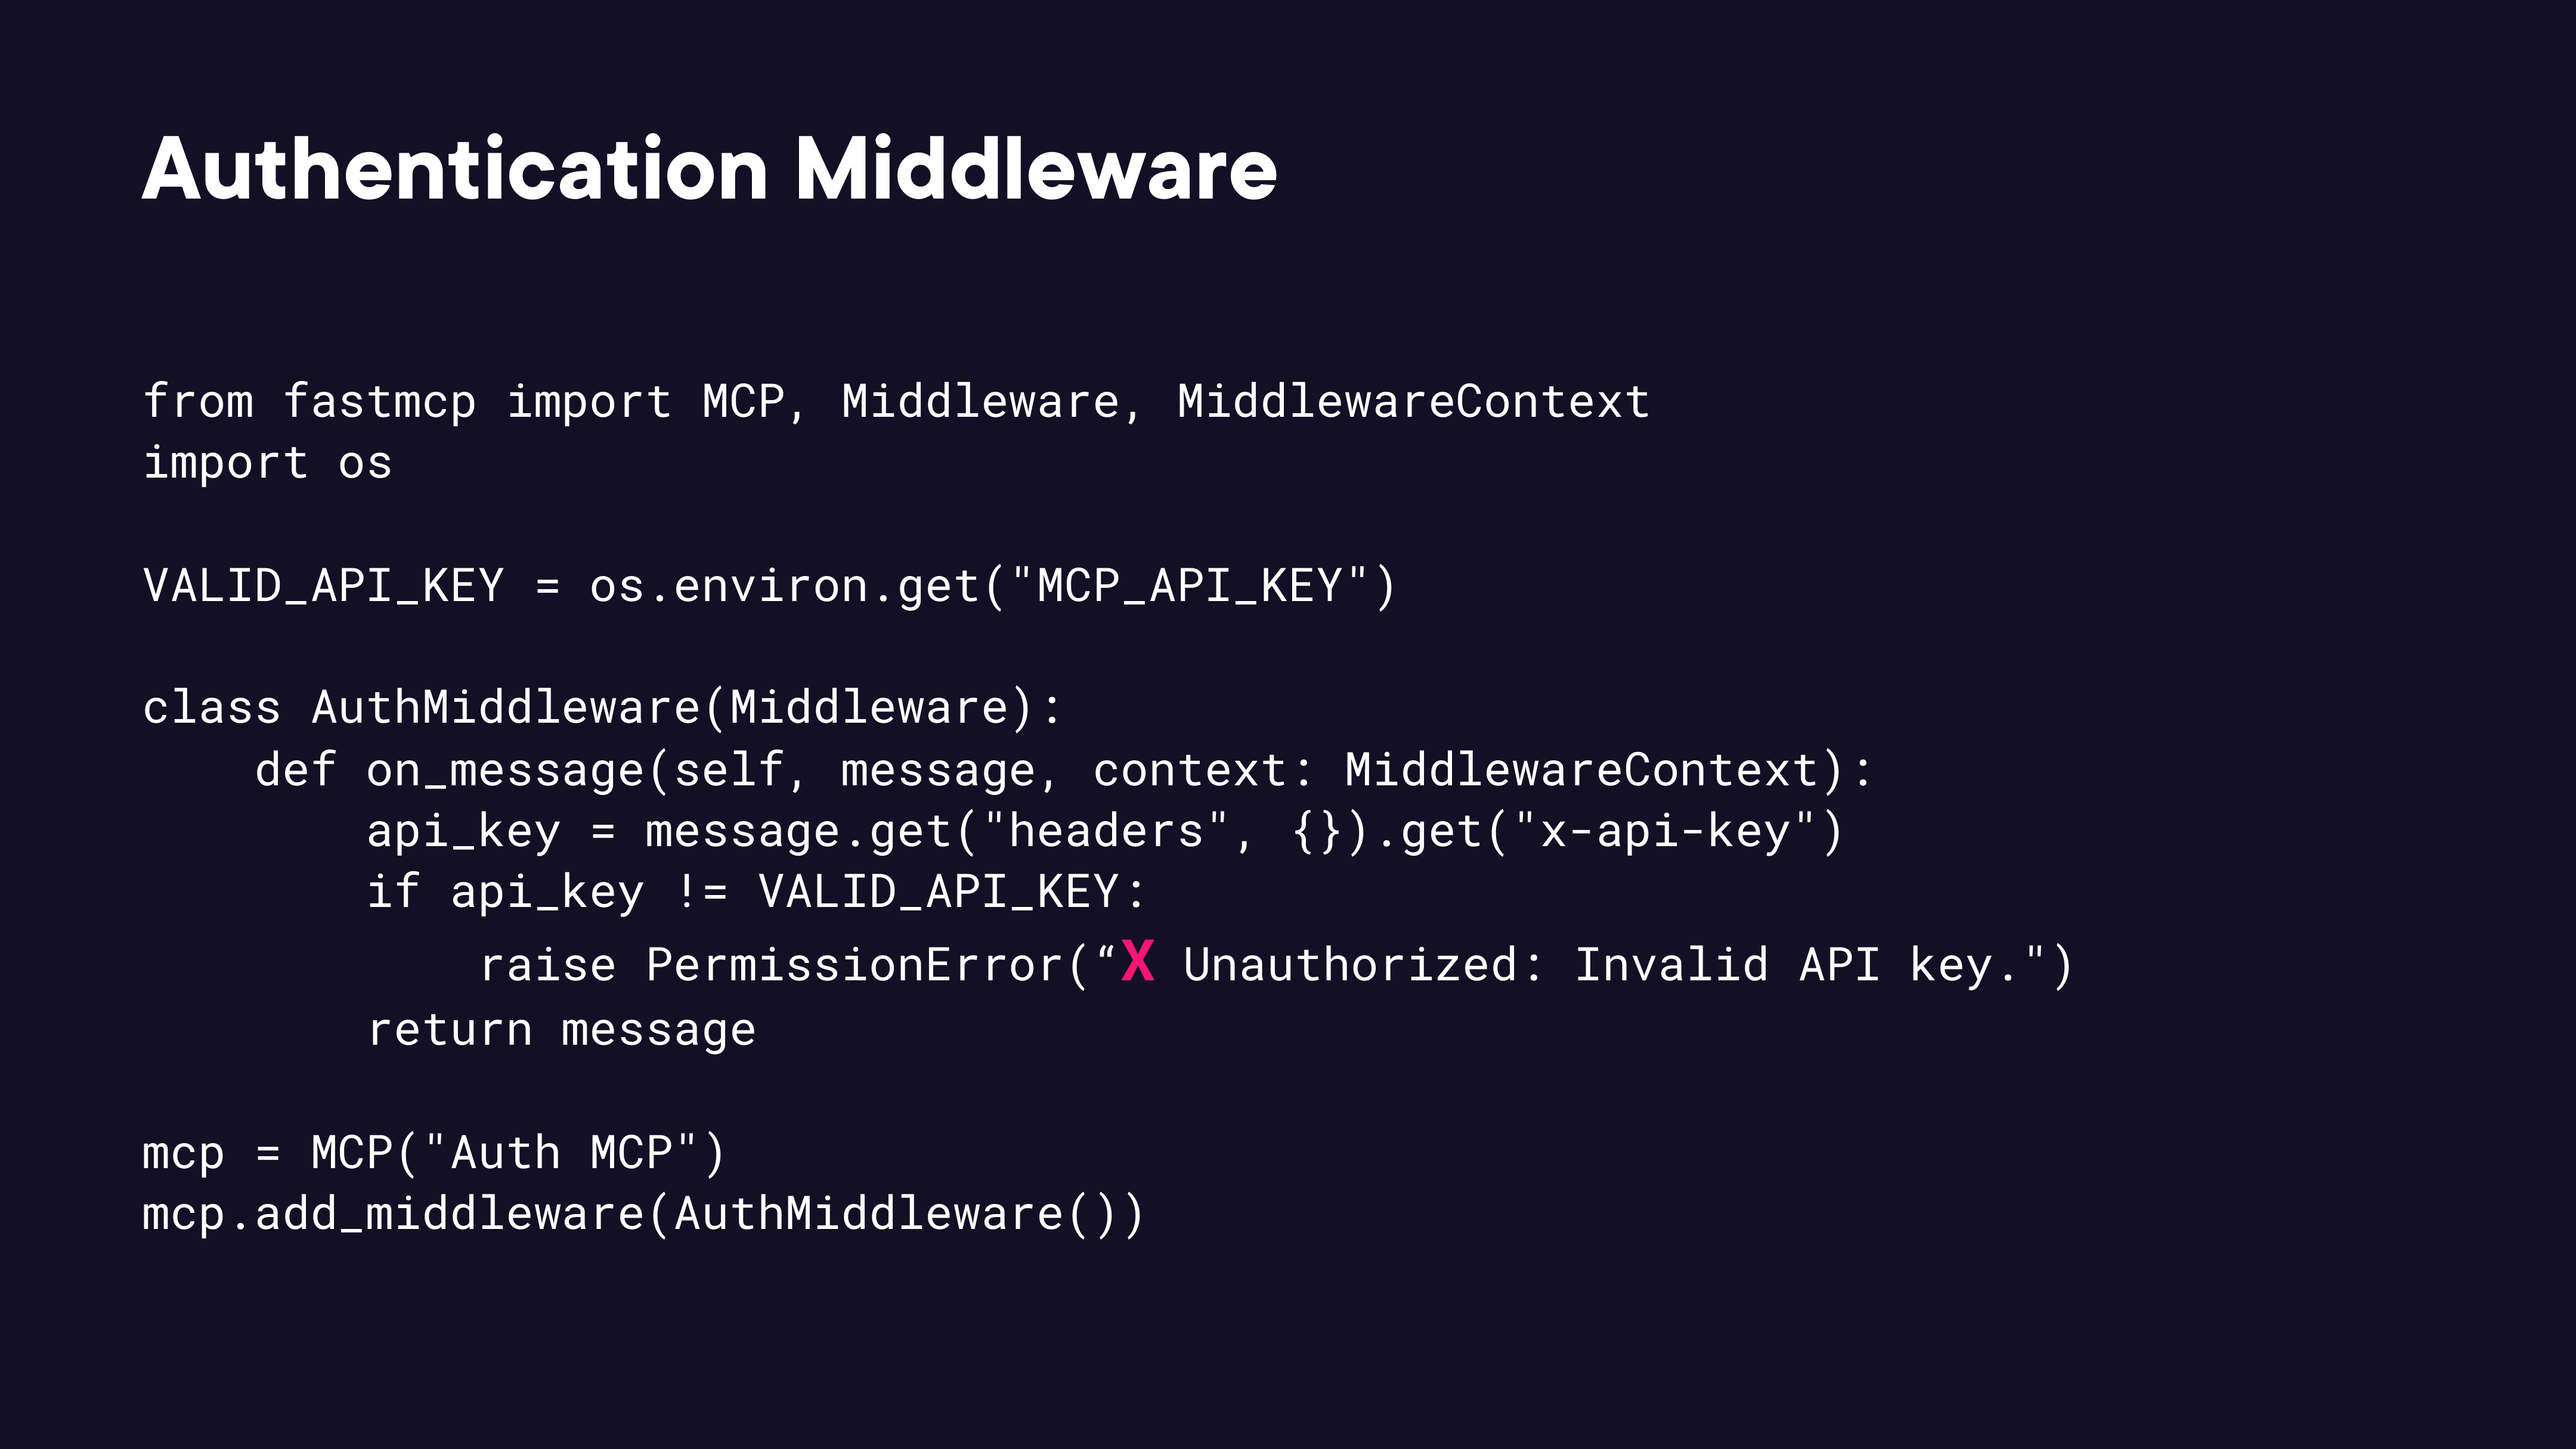

In [6]:
render_diagram(Path("assets/05-auth-middleware.png"))

#### Rate Limiting Middleware

Tracks request timestamps per `client_id` in a sliding window. If a client exceeds the limit, a `RateLimitExceeded` exception is raised before any tool runs:


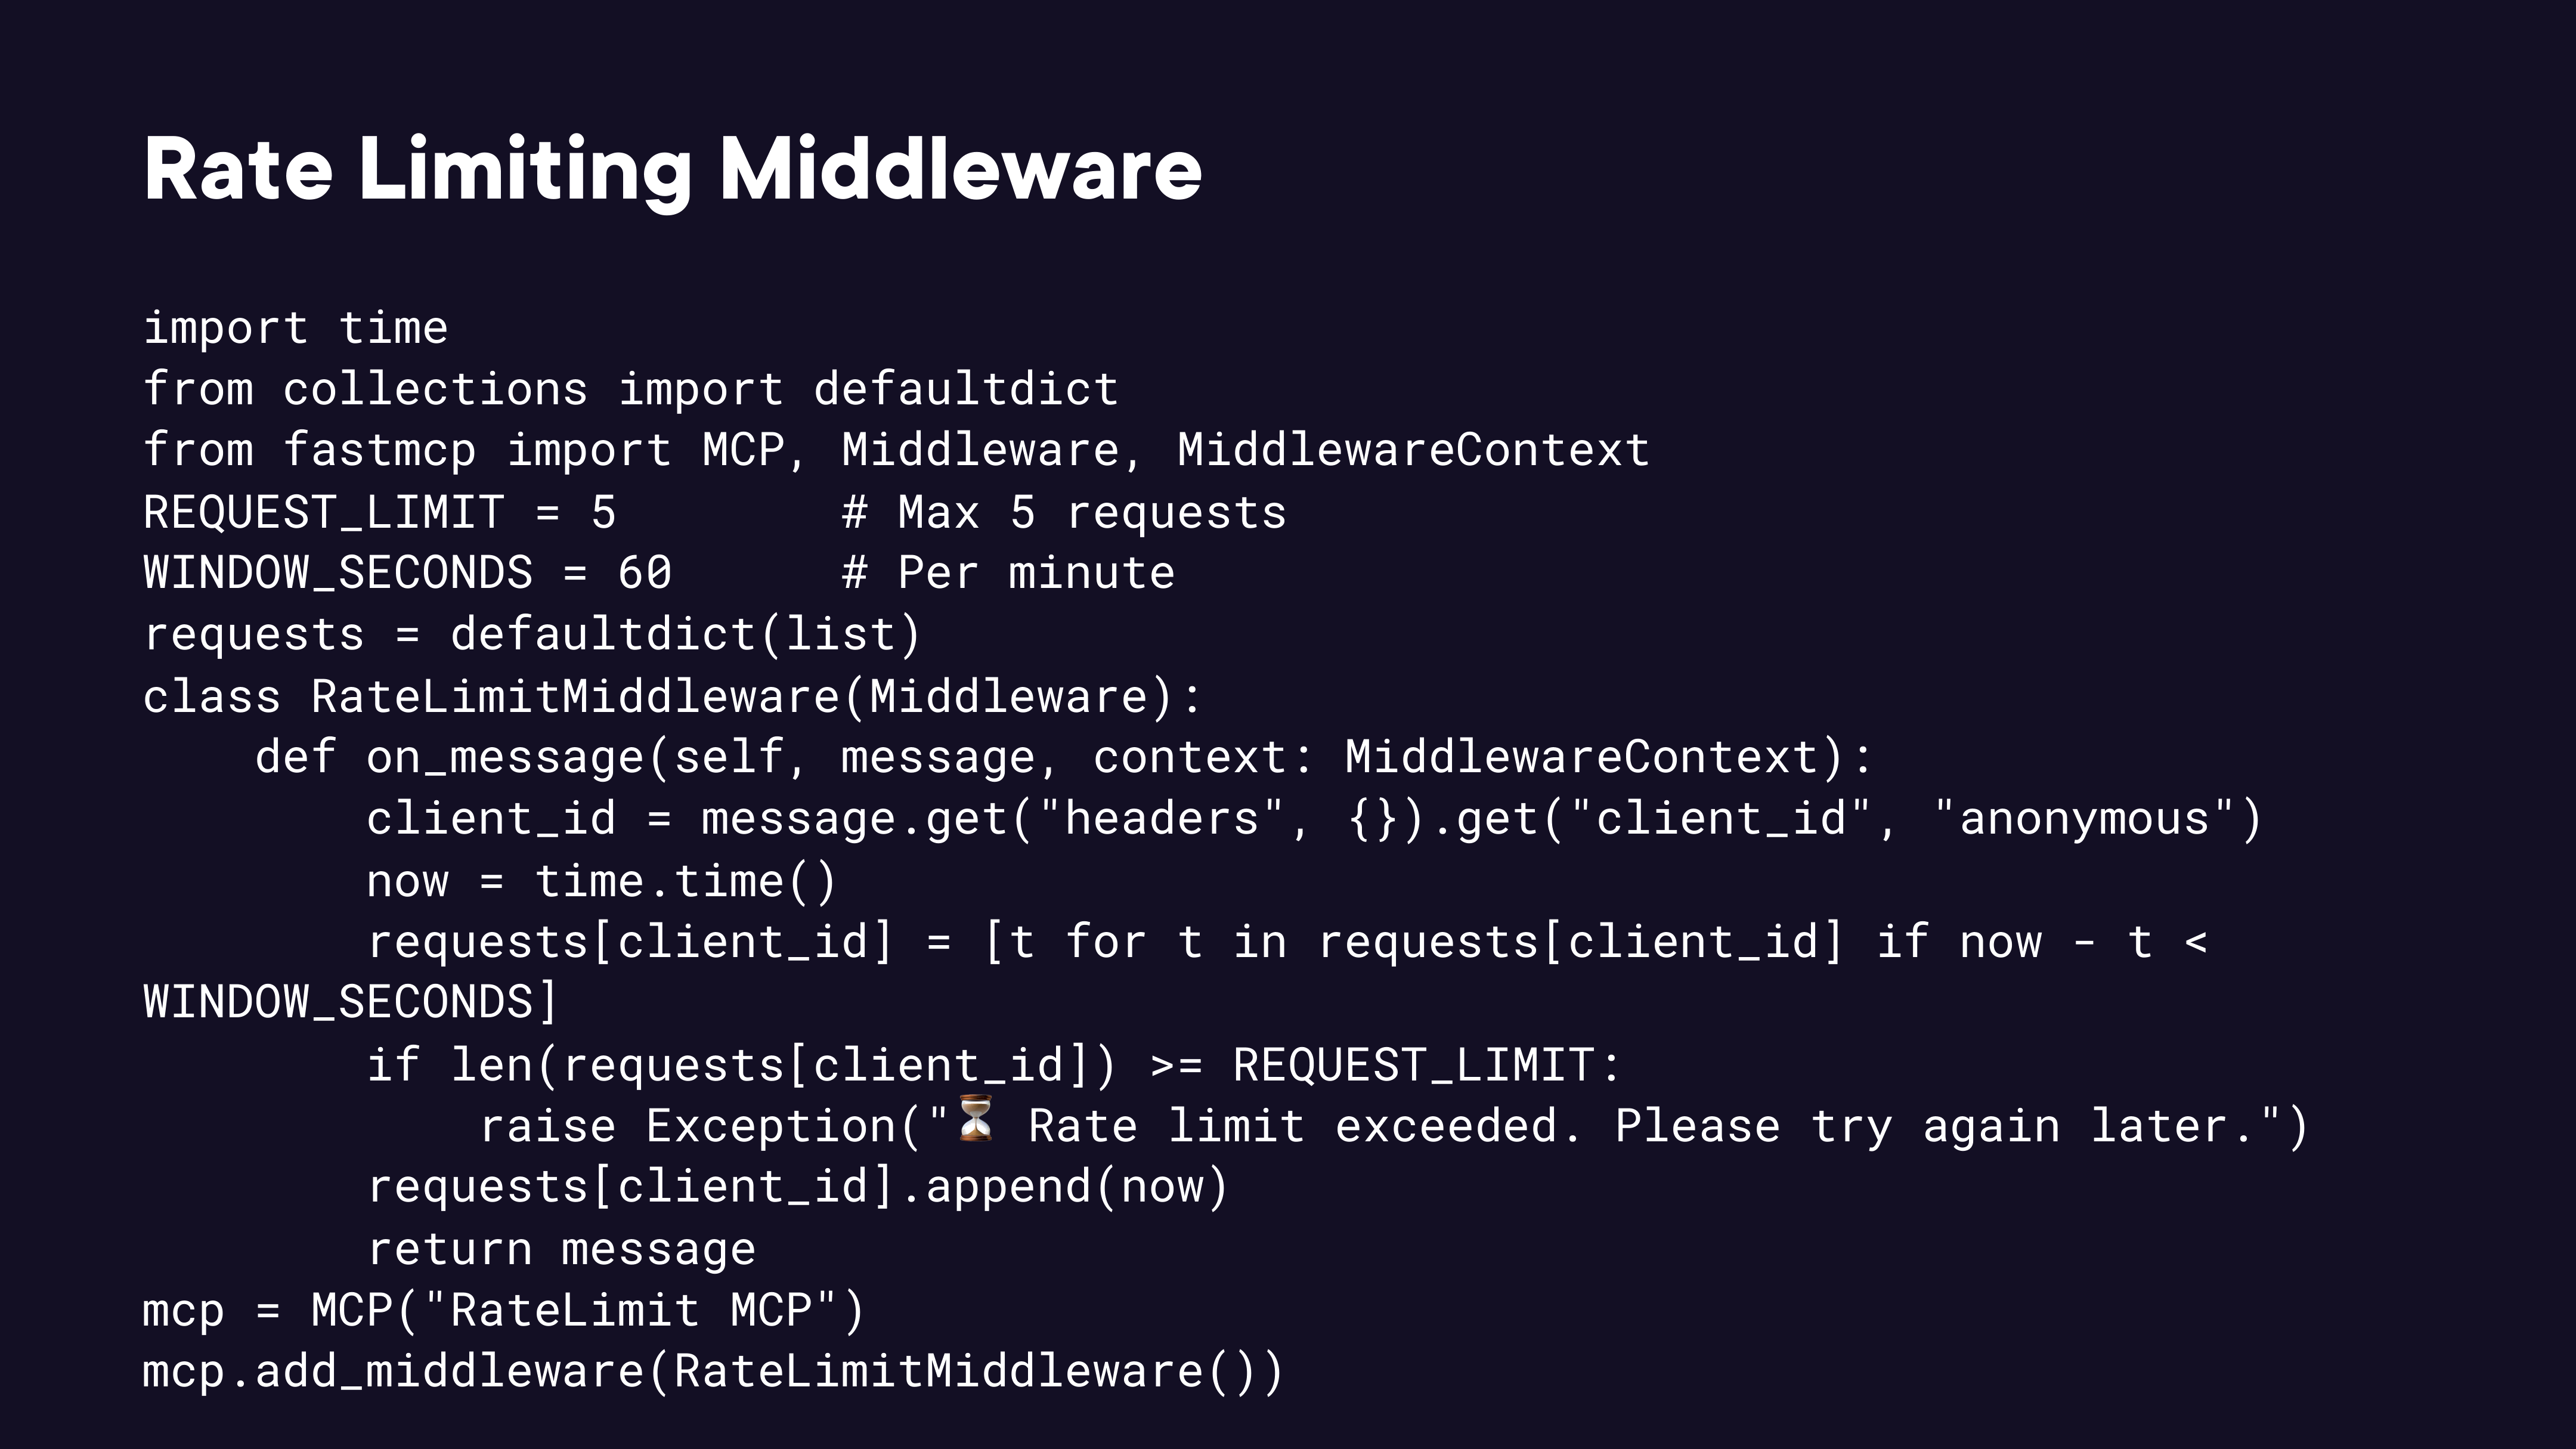

In [7]:
render_diagram(Path("assets/06-rate-limit-middleware.png"))

#### Request Tracing Middleware

Assigns a `trace_id` to every request (from the `x-trace-id` header or a generated UUID) and stores it in `context.metadata`. The same trace ID appears in both the message hook and the tool-call hook, correlating the full lifecycle of a request:


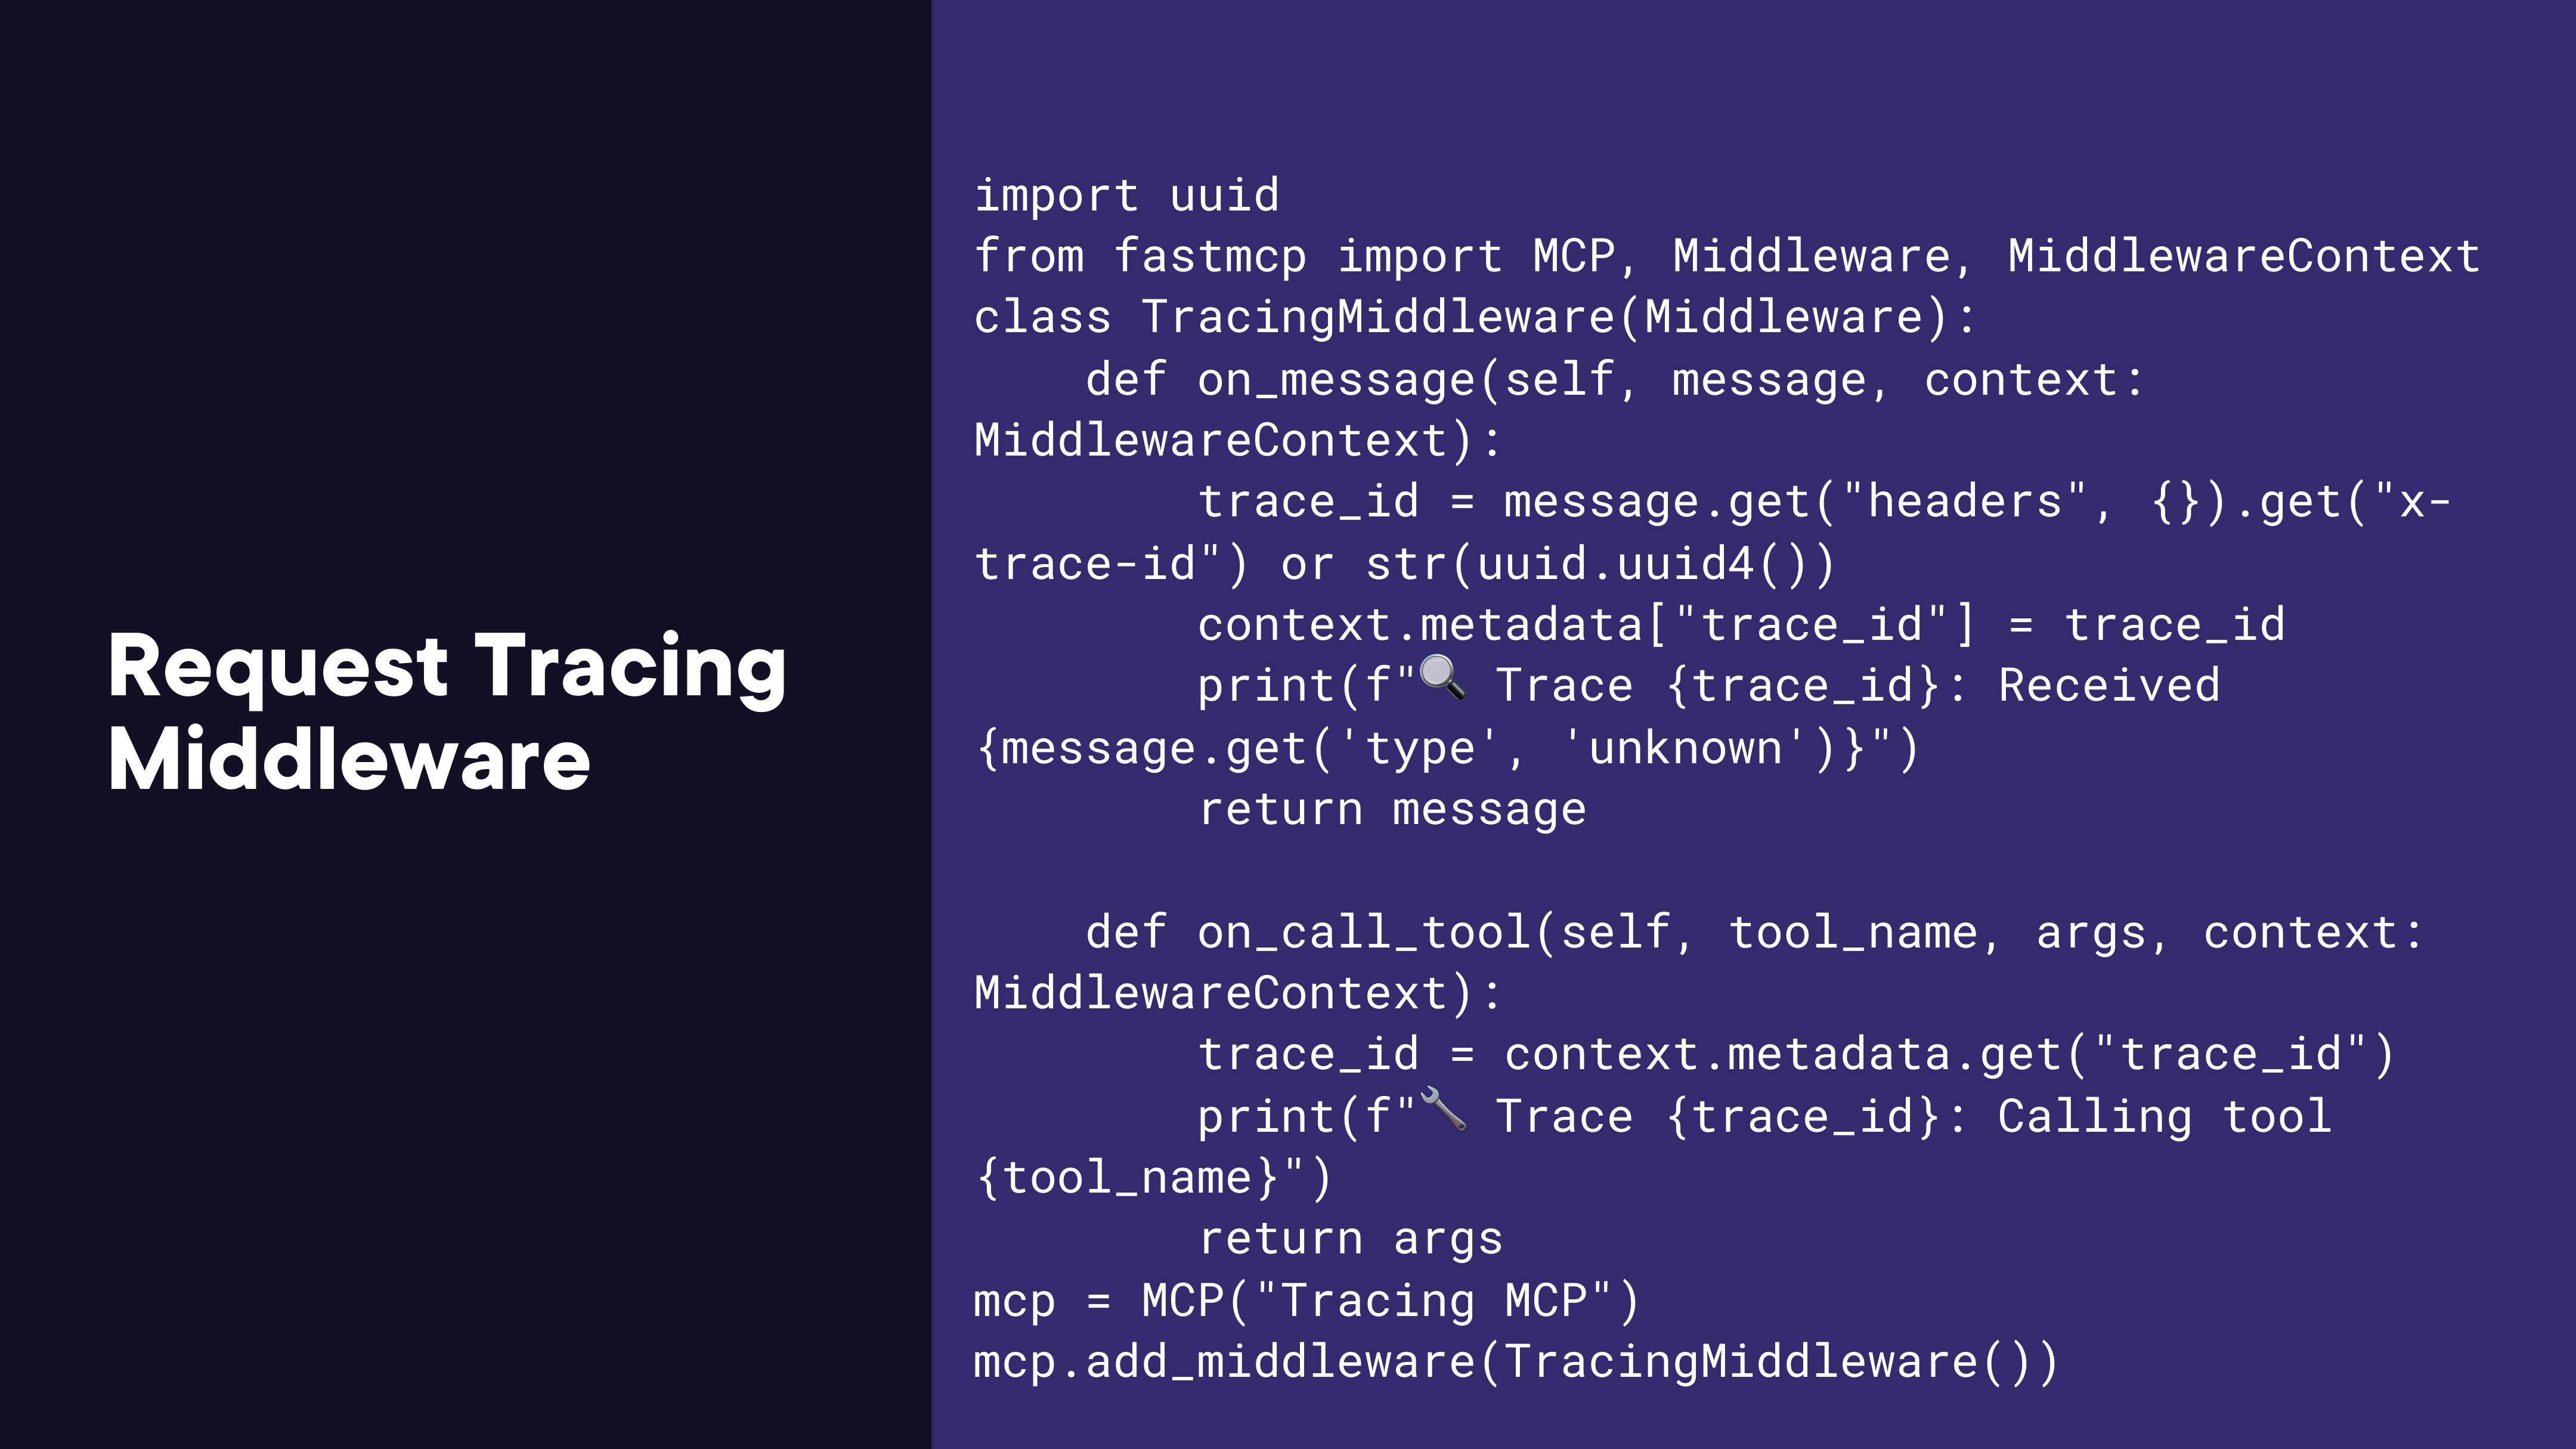

In [8]:
render_diagram(Path("assets/07-request-tracing-middleware.png"))

#### Combining Middleware Layers

Register multiple middleware with `mcp.add_middleware()`. They execute in registration order — auth first, then rate limiting, then tracing:


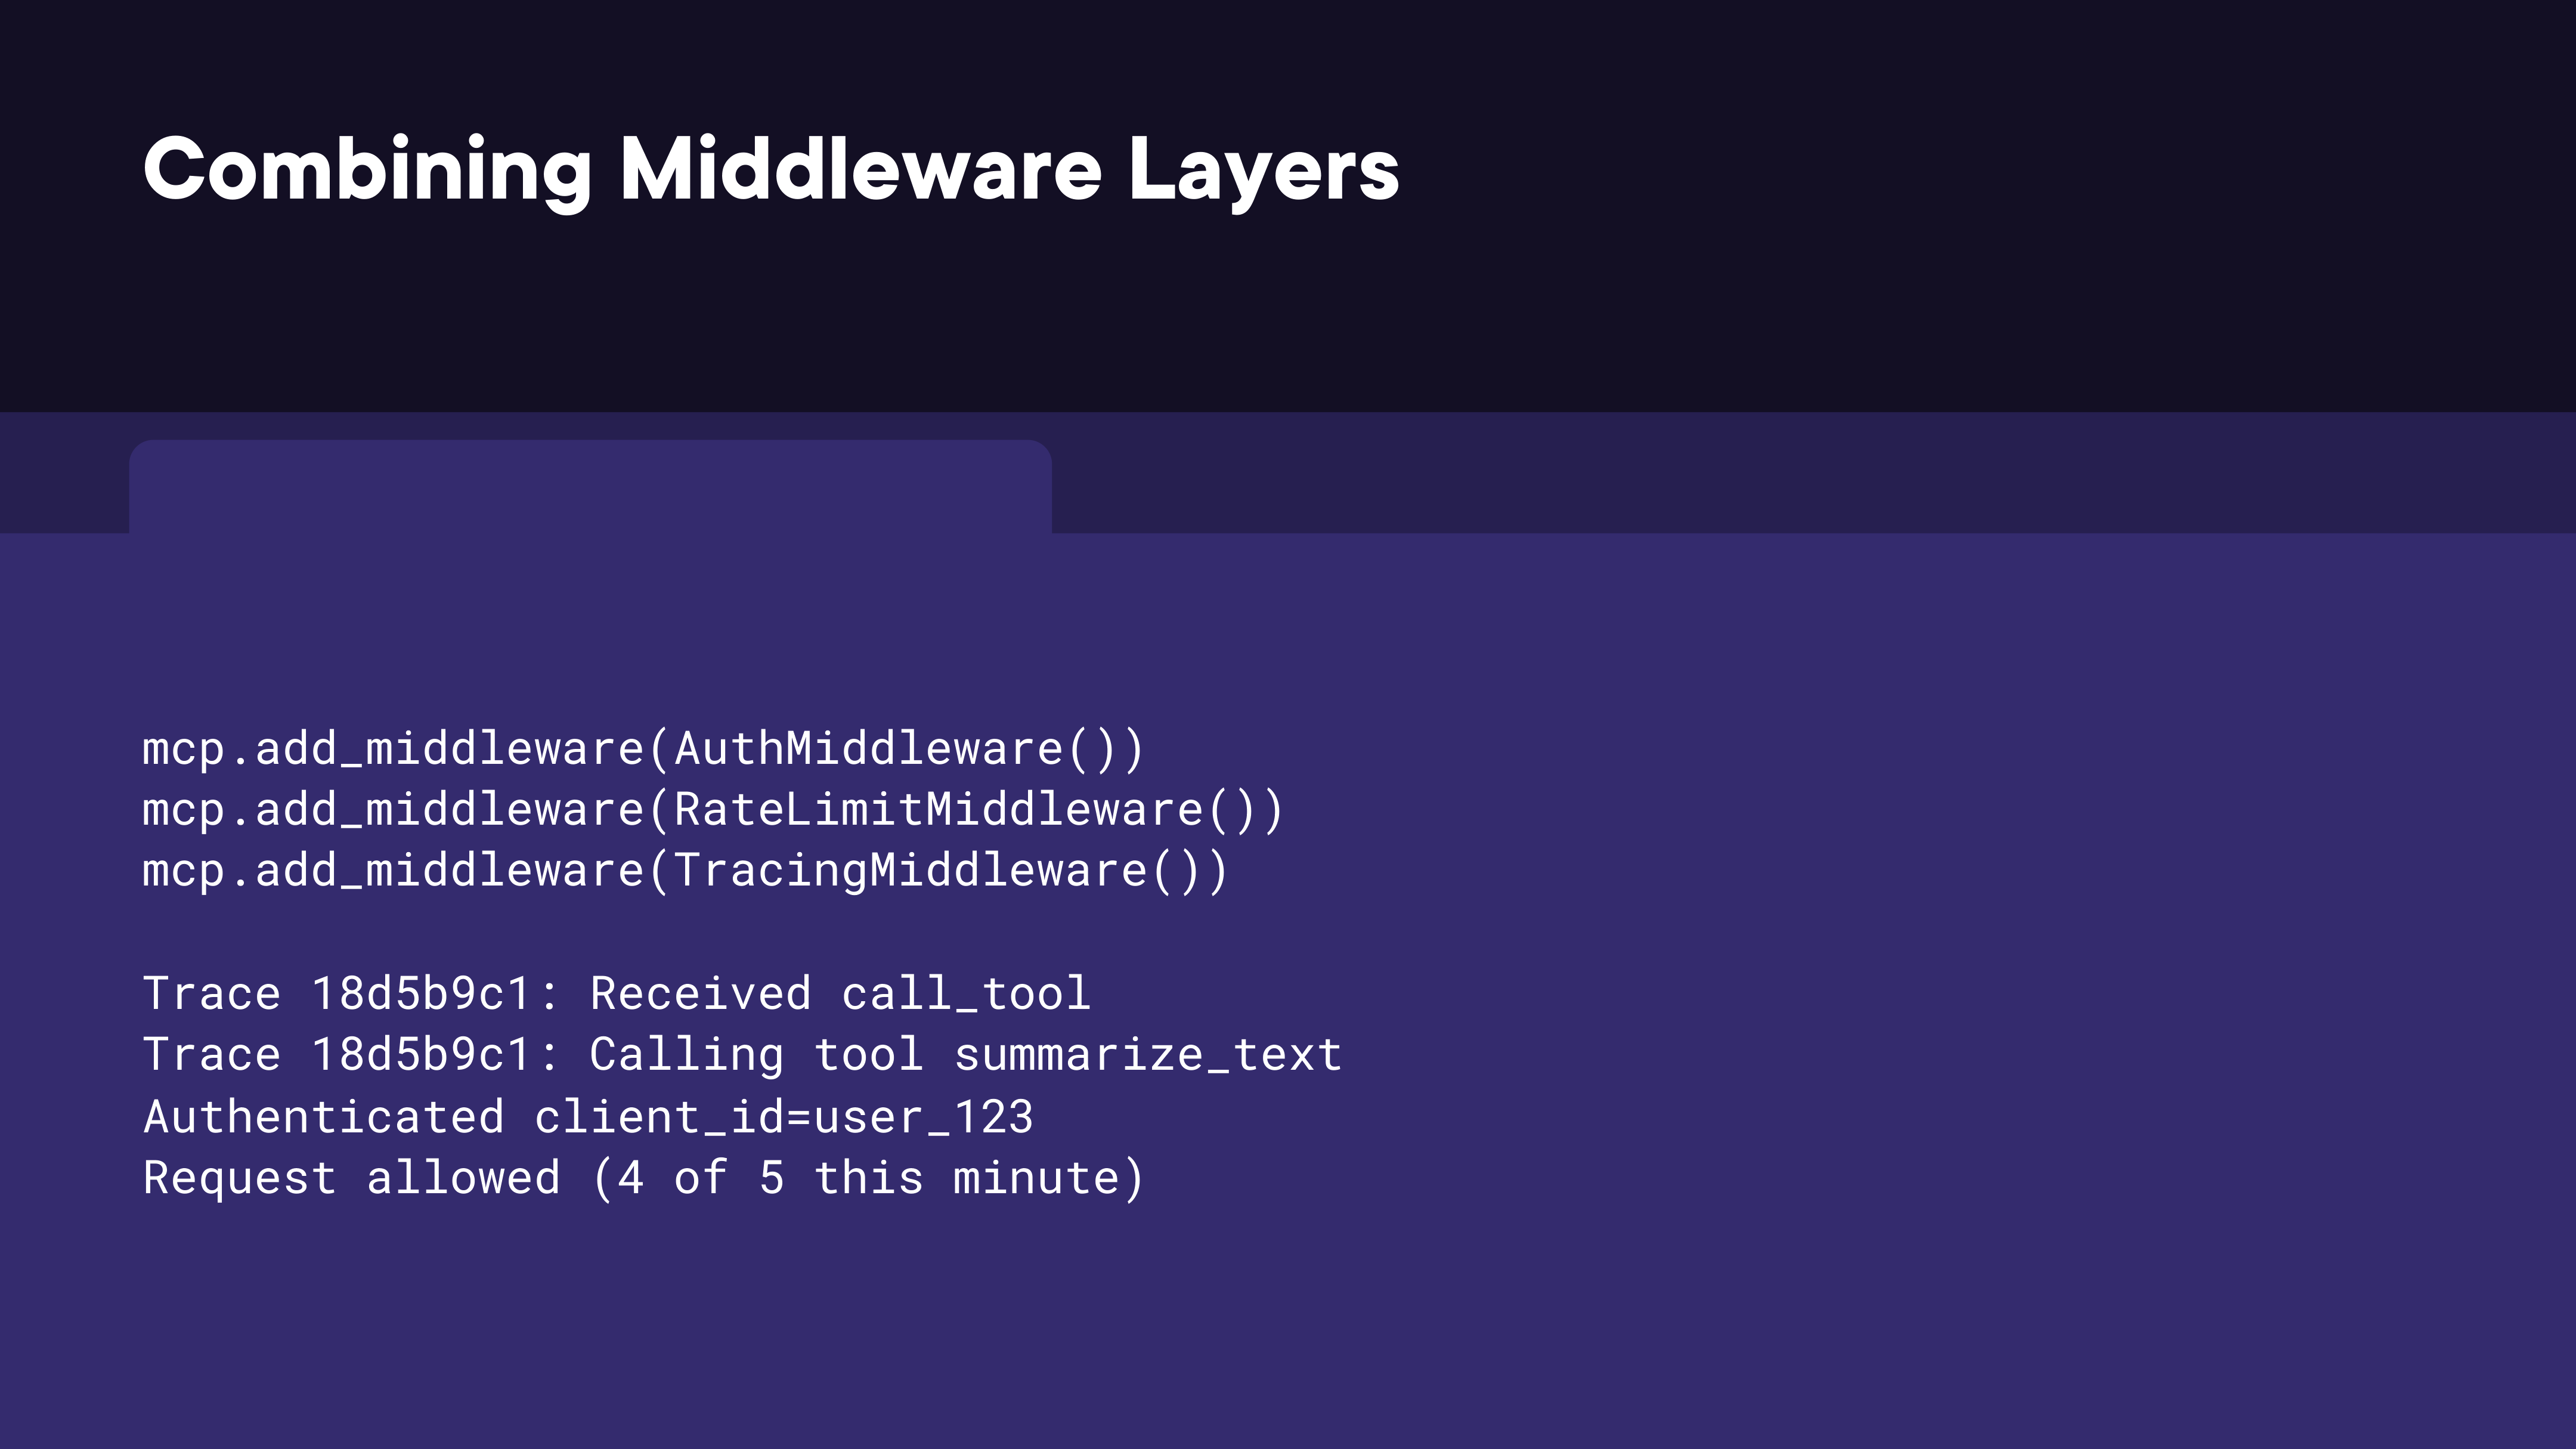

In [9]:
render_diagram(Path("assets/08-combining-middleware.png"))

### Debug Mode and Observability

#### Enabling Debug Mode

```python
# Via command line
python server.py --debug

# Programmatically
mcp.run(debug=True)
```

#### Inspecting the Middleware Stack

Add a tool that returns the names of all registered middleware, useful for verifying configuration at runtime:

```python
@mcp.tool()
def show_middleware_stack() -> list[str]:
    return [mw.__class__.__name__ for mw in mcp._middlewares]
# Returns: ["AuthMiddleware", "RateLimitMiddleware", "TracingMiddleware"]
```

#### Inspecting Registered Tools

```python
@mcp.tool()
def show_registered_tools() -> dict:
    tools = {}
    for t in mcp.tools.values():
        tools[t.name] = {
            "description": t.description,
            "input_schema": t.input_model.schema(),
            "output_schema": t.output_model.schema(),
        }
    return tools
```

#### Observability Metrics via Middleware

Collect per-tool call counts and average latency with a middleware decorator:

```python
import time
from collections import defaultdict

metrics = defaultdict(lambda: {"calls": 0, "errors": 0, "avg_latency": 0.0})
```


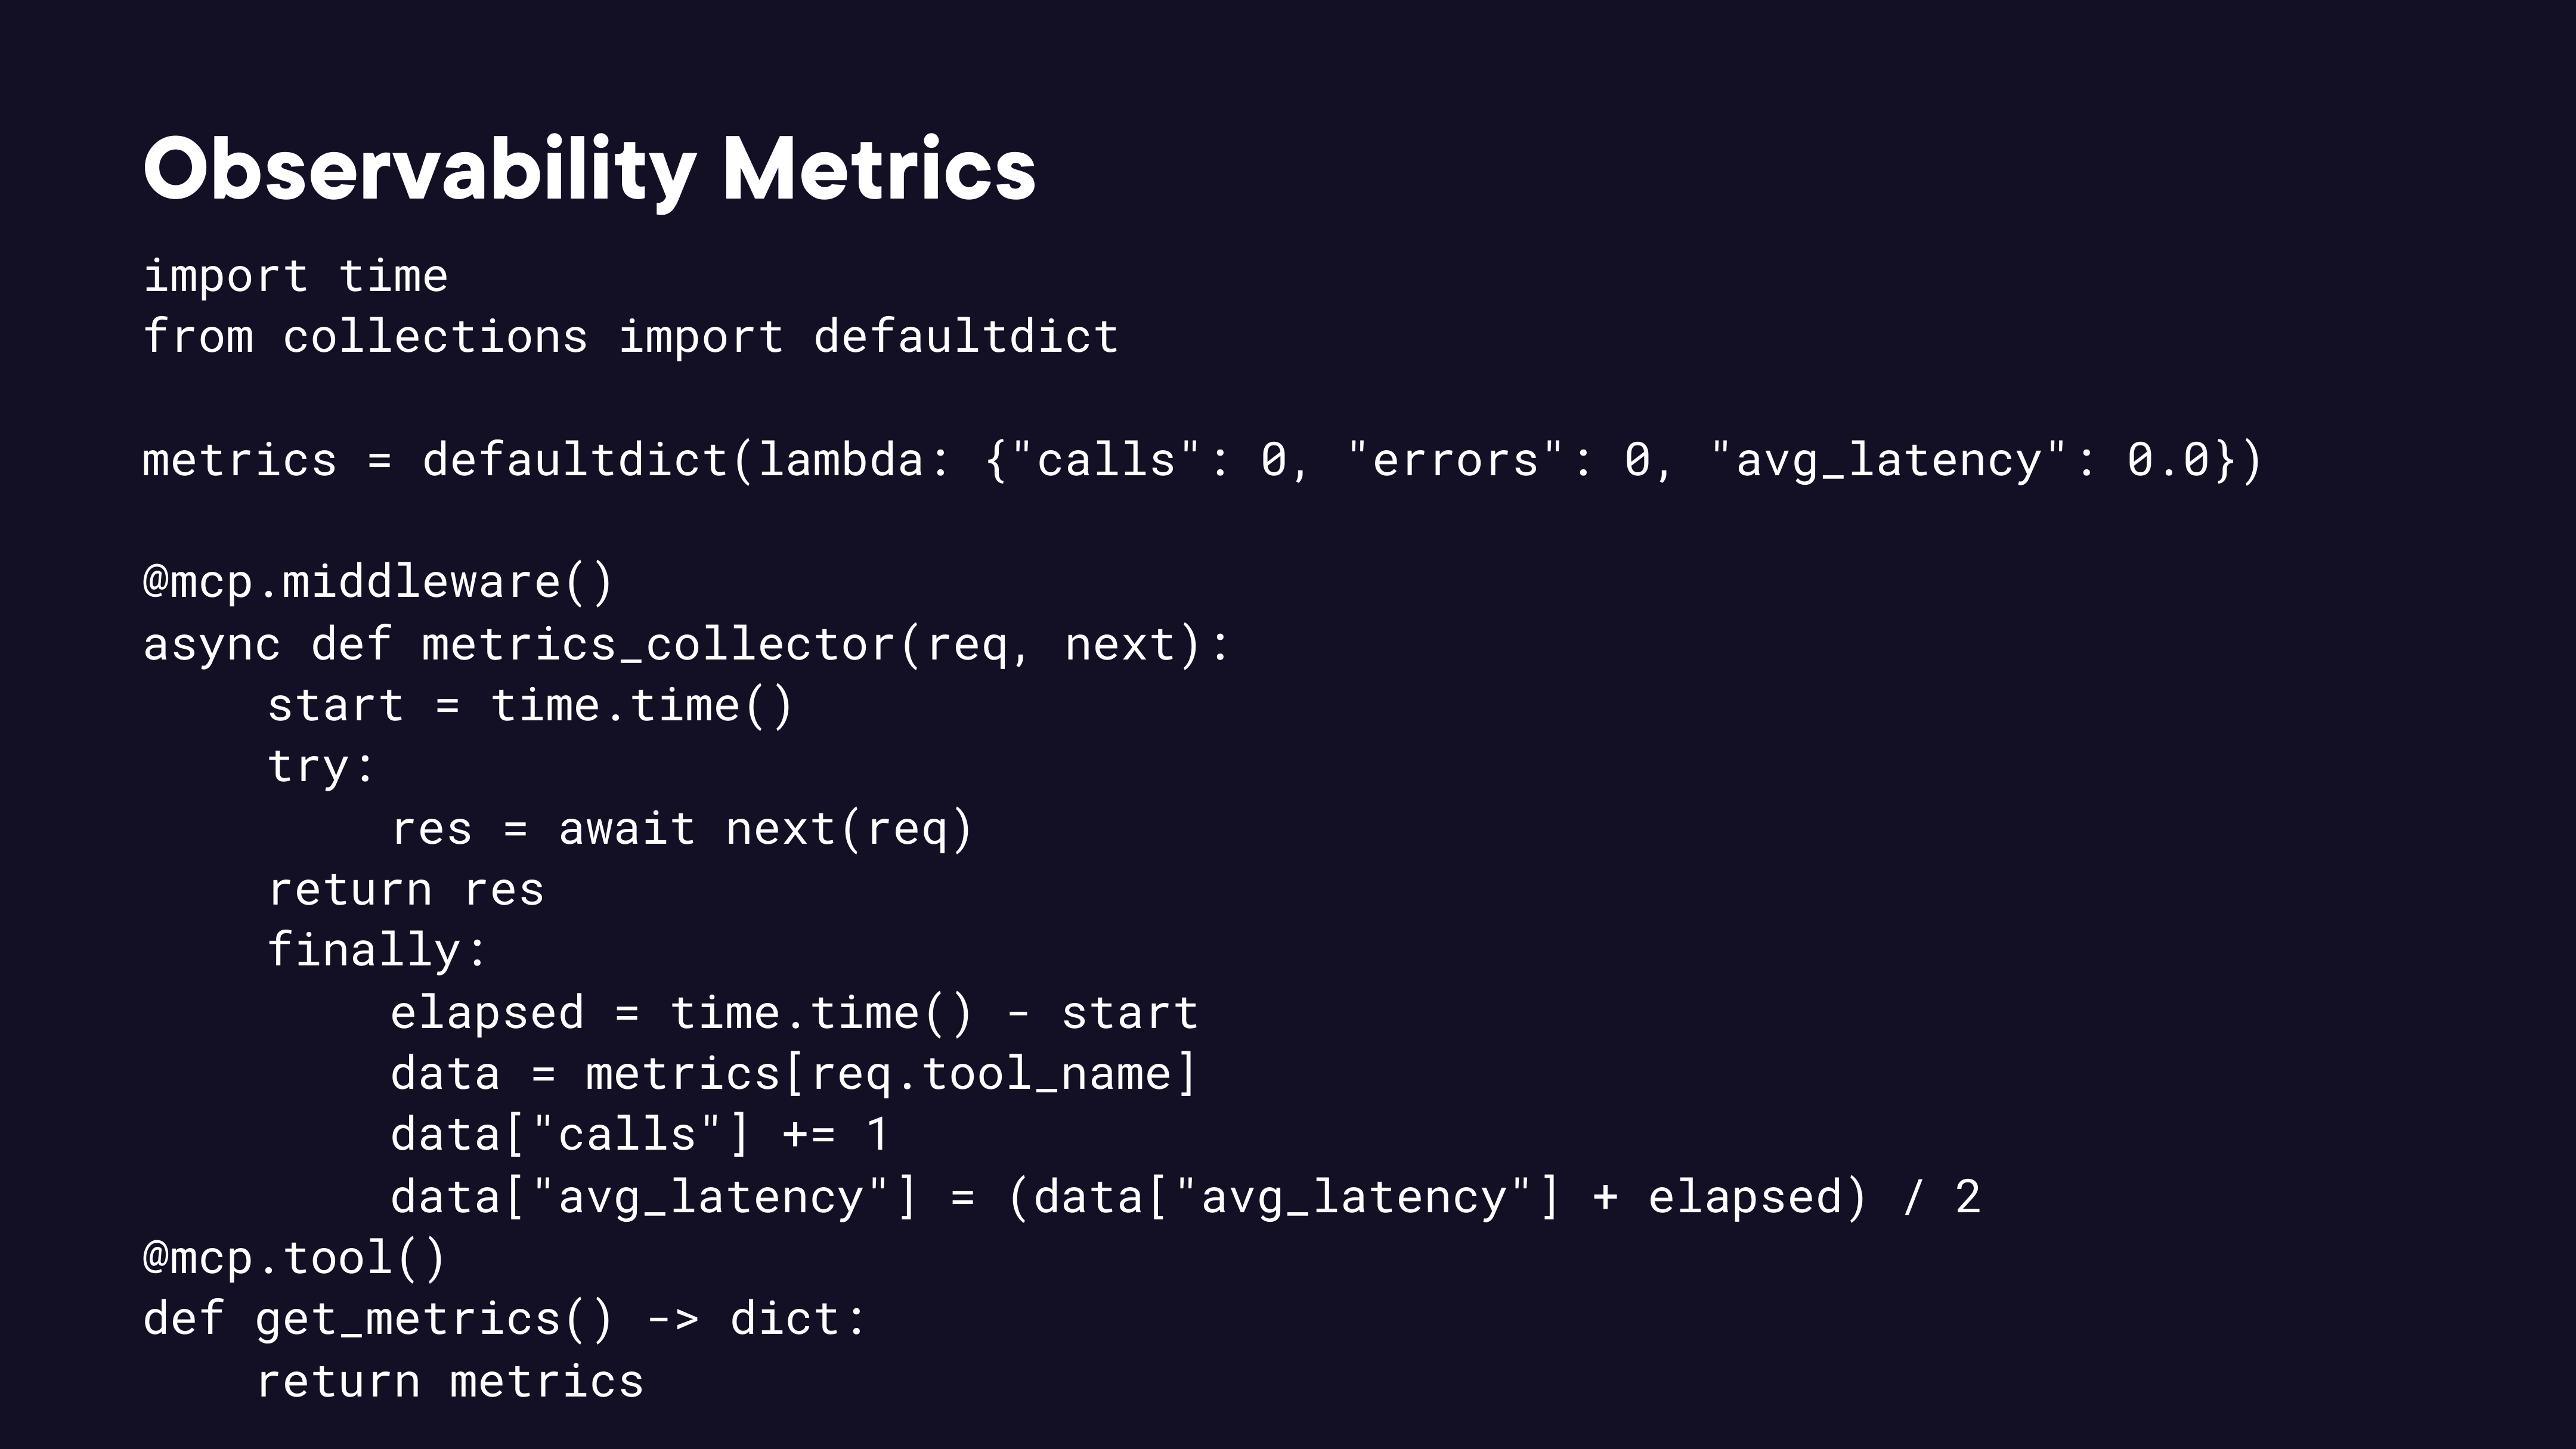

In [10]:
render_diagram(Path("assets/09-observability-metrics.png"))

#### OpenTelemetry Integration

For production observability, instrument your server with OpenTelemetry and export traces to any OTLP-compatible backend (Jaeger, Honeycomb, Datadog, etc.):


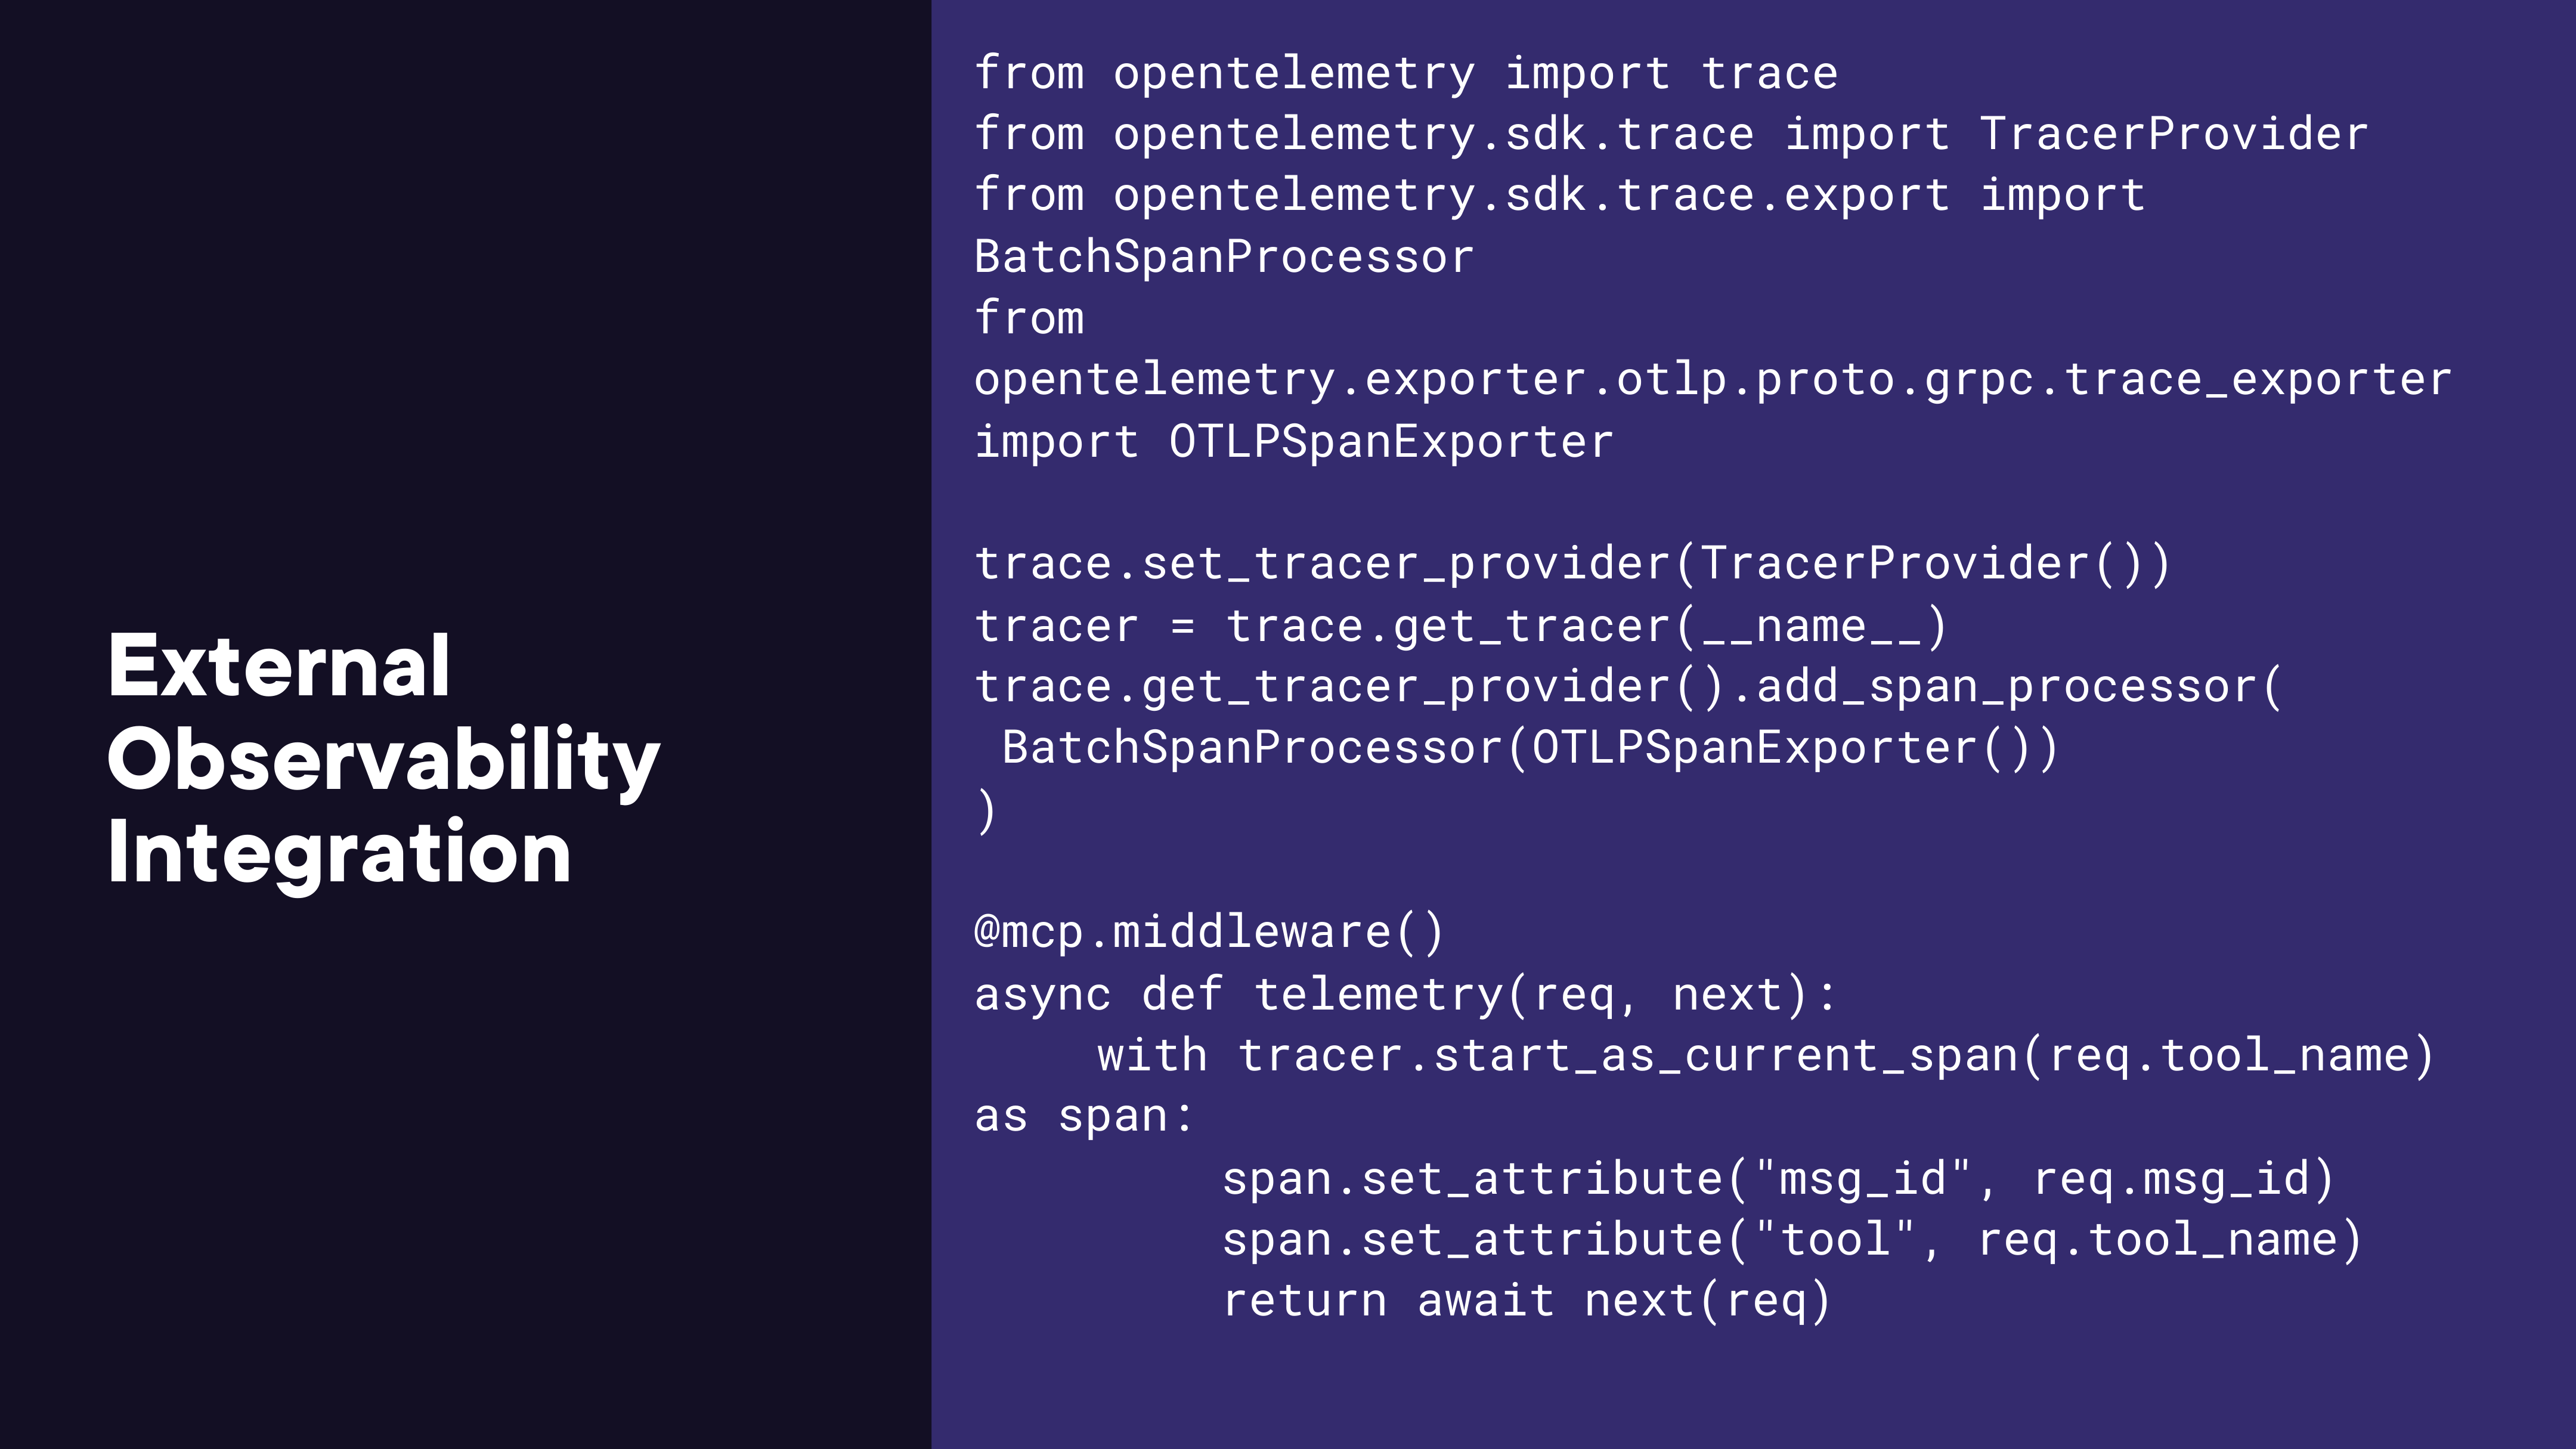

In [11]:
render_diagram(Path("assets/10-opentelemetry-integration.png"))

Each tool call becomes an OpenTelemetry span with `msg_id` and `tool` attributes attached. The `BatchSpanProcessor` batches and exports spans asynchronously so observability overhead is minimal.

### Security and Policy Enforcement

#### Key Risks

- **Unauthorized access** — unauthenticated callers invoking sensitive tools
- **Privilege escalation** — a tool performing actions beyond its intended scope
- **Sensitive data exposure** — returning secrets, PII, or internal data in tool responses
- **Dependency risk** — unpinned packages introducing vulnerabilities
- **Transport insecurity** — serving over plain HTTP without TLS

#### Built-in Security Features

FastMCP provides several protections out of the box:
- **OAuth integration** — authentication handled at the protocol layer, not per-tool
- **Schema-based validation** — all inputs validated against the declared schema before reaching tool code
- **FastMCP Cloud** — adds additional managed security infrastructure

#### Common Vulnerabilities to Guard Against

| Vulnerability | Description |
|---|---|
| Unrestricted tools | Every tool callable by any client without auth |
| Unvalidated input | Trusting raw strings without schema validation |
| Exposed endpoints | Internal or admin tools accessible to public clients |
| Poor logging hygiene | Logging sensitive data (tokens, PII) to stdout |
| Unpinned dependencies | `pip install fastmcp` without version pinning |

#### Security Checklist

- Manage secrets carefully — use environment variables, never hardcode
- Enforce authentication and authorisation on every endpoint
- Protect transports — use TLS for HTTP transports in production
- Implement auditing and observability — log tool calls and responses
- Mask and redact sensitive data before returning it
- Follow secure development hygiene — pin dependencies, run linters, scan for vulnerabilities

### FastMCP in Production

#### Containerising FastMCP Applications

Package your server as a Docker container for consistent, reproducible deployments:

```dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install -r requirements.txt
COPY . .
CMD ["python", "server.py"]
```

Set environment variables at container runtime — never bake secrets into the image:

```bash
docker run -e MCP_API_KEY=... -e DATABASE_URL=... my-mcp-server
```

#### Deploying to Cloud Platforms

FastMCP servers can be deployed to:
- **Vercel** — serverless deployment with automatic scaling
- **AWS Lambda** — event-driven, pay-per-invocation
- **Azure Functions** — Microsoft's serverless platform

#### Automated Testing

Write unit tests for every MCP tool before deploying:

```python
# Test that the tool accepts correct schema input
# Test that it produces the expected structured output
# Test that invalid inputs trigger predictable errors
```

Also:
- **Lint the codebase** — `ruff`, `flake8`, or `mypy` catch issues before runtime
- **Validate JSON schemas** — confirm tool schemas are valid before clients depend on them

#### Continuous Deployment with GitHub Actions

Automate the entire lifecycle with a GitHub Actions YAML workflow:

```yaml
name: Deploy MCP Server
on:
  push:
    branches: [main]
jobs:
  deploy:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with: { python-version: "3.11" }
      - run: pip install -r requirements.txt
      - run: python -m pytest
      - run: docker build -t my-mcp-server .
      # deploy step uses secrets from GitHub's encrypted Secrets
```

Store API keys and deploy tokens in GitHub's encrypted Secrets — never in the YAML file itself. Tag releases automatically to get semantic versioning on every deployment.